<center><h1>Leonez_Teresa_HW4</h1></center>
<br>
<br>

Name: Teresa Leonez
<br>
Github Username: ttl229
<br>
USC ID:  9630346635

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [119]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns

import statsmodels.api as sm
from scipy.stats import norm

from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [4]:
# Global variables
# Set column names as global variable
column_names = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23'
               ]

# Set series names for easier identification as global variable
series_names = {
    '1': 'average: chest & ankle A', '2': 'variance: chest & ankle A',
    '3': 'average: chest & ankle B', '4': 'variance: chest & ankle B',
    '5': 'average: ankle A & ankle B', '6': 'variance: ankle A & ankle B',
}

# Set plain english word replacement for the stats
stat_words = {'min': 'lowest', 'max': 'highest', 'mean': 'typical',
              'median': 'median', 'sd': 'variation in',
              'q1': '25th pct', 'q3': '75th pct'}

How to read the data: Each recording has 3 sensors (chest, ankle 1, ankle 2). 
average = strength of signal between sensors
variance = how much the signal changed between sensors
time-series, each instance is one recording over 2 minutes of one activity

In [108]:
# Load functions
# Function to load dataset for multiple dataset loading
def load_instance(filepath):
    df = pd.read_csv(filepath, comment ='#', header=None, names=column_names, sep=r'[,\s]+', engine='python')
    return df

# Function to get time-domain features for one dataset
def get_features(df)-> dict:
    sensors = df.drop(columns='time')  # Drop the time column 
    stats = {
        'min': sensors.min(),         # Gets min from data
        'max': sensors.max(),         # Gets max from data
        'median': sensors.median(),   # Gets median from data
        'mean': sensors.mean(),       # Gets mean 
        'sd': sensors.std(),          # Gets standard deviation data
        'q1': sensors.quantile(.25),  # Gets Q1 data
        'q3': sensors.quantile(.75),  # Gets Q3 data
    }

    features = {}  # sets up dictionary to store features for all datasets
    for stat_name, values in stats.items():
        for i, value in enumerate (values, start=1): 
            features[f'{stat_name}_{i}'] = value
    return features

# Function to split files into test and training data
def is_test(folder, n):
    if folder.startswith("bending"):  # if dataset is in bending1 and bending2 
        return n <= 2                 # pull dataset1 and dataset2 from bending1 and bending2
    return n <= 3      # pull dataset1, dataset2, dataset3, from all other folders


# Function for Python Bootstrapped resampling (Question iii.)
def bootstrap_column_std(column, n_bootstrap=1000, alpha=.10):   
    """ Takes parameters of column name, n for bootstrap with default 1000 """
    lower_percentile = 100* (alpha/2)  # 
    upper_percentile = 100* (1-(alpha/2))
    bootstrap_stds = [] # Holds the bootstrap standard deviations
    # bootstrap calculation 
    column_length = len(column)
    for i in range(n_bootstrap): # Repeat n number of times
        sample_result = column.sample(n=column_length, frac=None, replace=True, random_state=i) # Get sample
        sample_std = sample_result.std()
        bootstrap_stds.append(sample_std) # Store sample std in bootstrap stds list
    return np.percentile(bootstrap_stds, [lower_percentile, upper_percentile]) 
    """  Returns stds as list, upper and lower percentile """

# Function to relable feature description for comprehension
def relabel_sensors(feature): 
    stat, series, *part = feature.split('_')          # split the 'min_1' to min, 1, *part catches 'part1'
    label = f"{stat_words[stat]} | {series_names[series]}"
    if part:
        label += f" ({part[0]})"
    return label

# Function to check if column in dataframe contains data for specific activity (ie. bending)
def is_activity(df: pd.DataFrame, label: str)-> pd.Series:
    result = df['activity'].str.startswith(label)
    return result

# Function to split data into n pieces
def get_split_features(df, n):
    row_groups = np.array_split(np.arange(len(df)), n)   # split row numbers into n groups
    parts = [df.iloc[rows] for rows in row_groups]        # split df into n pieces
    features_dict = {}  # create empty dictionary to store data
    for part_n, part in enumerate(parts, start=1):
        features = get_features(part)
        for key, value in features.items():
            features_dict[f'{key}_part{part_n}'] = value
    return features_dict

# Function to build df with changeable 'l'
def build_features_df(l: int) -> pd.DataFrame:  # Returns Dataframe
    rows = []
    for filepath in dataset_files:      # Loop through the dataset files to load features to a list
        activity = filepath.parent.name # adjusts name of file to include activity marker
        n = int(filepath.stem.replace('dataset', ''))
        df = load_instance(filepath)
        features = get_split_features(df, l)
        features['activity'] = activity
        features['n']=n
        features['split'] = 'test' if is_test(activity, n) else 'train' # Splits files into test and train data
        rows.append(features)
    return pd.DataFrame(rows)

# Function to print the scores visibly, rounded to 3 decimals
def print_score_summary(scores, k=5):
    print(f"Folds with k={k}")
    for i, score in enumerate(scores, start=1):
        print(f'#{i}: {score:.3f}')
    print(f'Mean score: {scores.mean():.3f}') # Print mean score rounded

# Helper function to build X, y for one value of l 
def build_xy(l: int, stats: list, split_label: str = 'train', binary: bool=True) -> tuple:  # 
    df_l = build_features_df(l)
    split_df = df_l[df_l['split'] == split_label].copy()       # Keep only rows that are in the 'split_label' set, default is 'train'
    feature_cols = [col for col in split_df.columns if col.split('_')[0] in stats]   # Keep only columns that include 'stats' in passed list ie. 'mean' 'max'
    X = split_df[feature_cols]

    # Allow for binary or multinomial calculation
    if binary:
        y = is_activity(split_df, 'bending').astype(int)
    else:
        y = split_df['activity']
        
    return X, y

# Helper function to make pipeline
def make_pipeline(p: int) -> Pipeline:
    return Pipeline([           # use Pipeline to keep folds separate
        ('scale', StandardScaler()),
        ('select', RFE(LogisticRegression(max_iter=1000), n_features_to_select=p)),  # create RFE model and select p attriburtes
        ('model', LogisticRegression(max_iter=1000)),
    ])

    
#  Define resuable function to test l value for X, y (question 2.a.iii.)
def evaluate_l(l: int, stats: list, cv, p_max=20) -> list: # Returns results as list
    X, y = build_xy(l, stats) # Build X,y using repeatable function

    # Use recursive feature-elimination where p = number of features used
    results = []
    for p in range(1, min(p_max, X.shape[1]) + 1):      # p is number of features up to number of columns
        pipeline = make_pipeline(p)
        
        scores = cross_val_score(pipeline, X, y, cv=cv)
        results.append({'l': l, 'p': p, 'score': scores.mean()})
    
    return results

# Function to show confusion matrix
def plot_confusion_matrix(model, X, y, title:str, labels=None):
    if labels is None:                             # added for multinomial processing
        labels = model.classes_ 
    # Show confusion matrix
    predicted_y = model.predict(X)                  # predict Y based on data
    cm = confusion_matrix(y, predicted_y)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='coolwarm', xticks_rotation=45)
    plt.title(title)
    plt.show()
    return cm


# Function for case controled sample in 2.b.vii.
def case_control_sample(X, y, seed: int=42) -> tuple:
    cases = y[y == 1].index            # select all rows where activity is 'bending'
    controls = y[y == 0].sample(n=len(cases), random_state=seed).index   # select equal of rows randomly where activity is 'not bending'
    idx = cases.union(controls)        # combines two lists of row labels
    return X.loc[idx], y.loc[idx]


# Function to make l1-penalized pipeline for question 2b.i
def make_l1_pipeline(c: float, solver: str = 'liblinear') -> Pipeline:
    l1_pipeline = Pipeline([
        ('scale', StandardScaler()),
        ('model', LogisticRegression(l1_ratio=1, solver=solver, C=c, max_iter=5000)),  
    ])
    return l1_pipeline


# Function to cross validate l and l1
def evaluate_l_l1(l: int, stats: list, cv, c_values, binary:bool = True) -> list:
    solver = 'liblinear' if binary else 'saga'   # Defaults to recommended using Liblinear package per hw
    X, y = build_xy(l, stats, binary=binary)
    results = []
    for c in c_values:
        c_pipeline = make_l1_pipeline(c, solver=solver)
        c_scores = cross_val_score(c_pipeline, X, y, cv=cv)
        results.append({'l': l, 'C': c, 'score': c_scores.mean()})
    return results

# Function to cross validate for naive bayes question 2c.ii
def evaluate_l_nb(l: int, stats: list, cv, model) -> dict:
    X, y = build_xy(l, stats, binary=False)
    scores = cross_val_score(model, X, y, cv=cv)
    results = {'l': l, 'score': scores.mean()}
    return results

def make_mnb_pipeline():
    pipeline = Pipeline([('scale', MinMaxScaler()),
                        ('model', MultinomialNB()),
                    ])
    return pipeline

Get the AReM Data Set

In [6]:
# Test that data is loading with function correctly
df = load_instance("AReM/bending1/dataset4.csv")

### (b) Splitting Data

In [7]:
# Set file names as list to extract features into new dataframe
dataset_files = sorted(Path("AReM").glob("*/*.csv"))

### (c) Feature Extraction

In [8]:
rows = []
for filepath in dataset_files:   # Loop through the dataset files to load features to a list
    activity = filepath.parent.name # adjusts name of file to include activity marker
    n = int(filepath.stem.replace('dataset', ''))
    
    df = load_instance(filepath)
    features = get_features(df)
    features['activity'] = activity
    features['n']=n
    features['split'] = 'test' if is_test(activity, n) else 'train' # Splits files into test and train data
    rows.append(features)

features_df = pd.DataFrame(rows) # Feed list of features into cleaned dataframe
print(features_df)

feature_columns = features_df.columns.drop(['activity', 'n', 'split']) # Drops the non data columns for std calculation

    min_1  min_2  min_3  min_4  min_5  min_6  max_1  max_2  max_3  max_4  ...  \
0   37.25    0.0   4.00    0.0  27.25    0.0  45.00   1.30  29.50   7.23  ...   
1   38.00    0.0   2.00    0.0  27.67    0.0  45.67   1.22  29.50   5.76  ...   
2   35.00    0.0   6.50    0.0  29.00    0.0  47.40   1.70  29.75   4.44  ...   
3   33.00    0.0   8.50    0.0  20.00    0.0  47.75   3.00  30.00   5.15  ...   
4   33.00    0.0   3.00    0.0  23.67    0.0  45.75   2.83  28.25   6.42  ...   
..    ...    ...    ...    ...    ...    ...    ...    ...    ...    ...  ...   
83  20.75    0.0   5.00    0.0   6.00    0.0  46.25  12.68  23.75   9.20  ...   
84  21.50    0.0   6.50    0.0   6.33    0.0  51.00  12.21  23.33   9.09  ...   
85  18.33    0.0   7.67    0.0   6.67    0.0  47.67  12.48  23.33   9.01  ...   
86  18.33    0.0   5.50    0.0   6.50    0.0  45.75  15.37  24.00   9.18  ...   
87  15.50    0.0   7.67    0.0   5.75    0.0  43.67  17.24  23.00   9.20  ...   

    q1_6     q3_1    q3_2  

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

Use training set to classify bending vs not bending (binary classification). 
- use scatter plot to depict features 'max', 'mean', and 'sd' from time series 1, 2, 6 of each instance
- use colors to separate 'bending' vs 'not bending'
Key:
series 1 = average of chest sensor to ankle A (strength of signal within activity)
series 2 = variance of chest sensor to ankle A (how much that signal changed within activity)
series 6 = variance of ankle A to ankle B (how much ankle A and ankle B signal changed --> distance and motion between ankles)

In [9]:
# Define training data
train_df = features_df[features_df['split'] == 'train'].copy()

# stratify data by binary classification 'bending' or 'other'
combined_bending = is_activity(train_df, 'bending') # Combine bending 1 and bending 2 data
train_df['label'] = np.where(combined_bending, 'bending', 'other') # Split data into binary classification
train_df.columns

Index(['min_1', 'min_2', 'min_3', 'min_4', 'min_5', 'min_6', 'max_1', 'max_2',
       'max_3', 'max_4', 'max_5', 'max_6', 'median_1', 'median_2', 'median_3',
       'median_4', 'median_5', 'median_6', 'mean_1', 'mean_2', 'mean_3',
       'mean_4', 'mean_5', 'mean_6', 'sd_1', 'sd_2', 'sd_3', 'sd_4', 'sd_5',
       'sd_6', 'q1_1', 'q1_2', 'q1_3', 'q1_4', 'q1_5', 'q1_6', 'q3_1', 'q3_2',
       'q3_3', 'q3_4', 'q3_5', 'q3_6', 'activity', 'n', 'split', 'label'],
      dtype='str')

In [10]:
# Verify labels correct (expected 60 other, 9 bending)
train_df['label'].value_counts()

label
other      60
bending     9
Name: count, dtype: int64

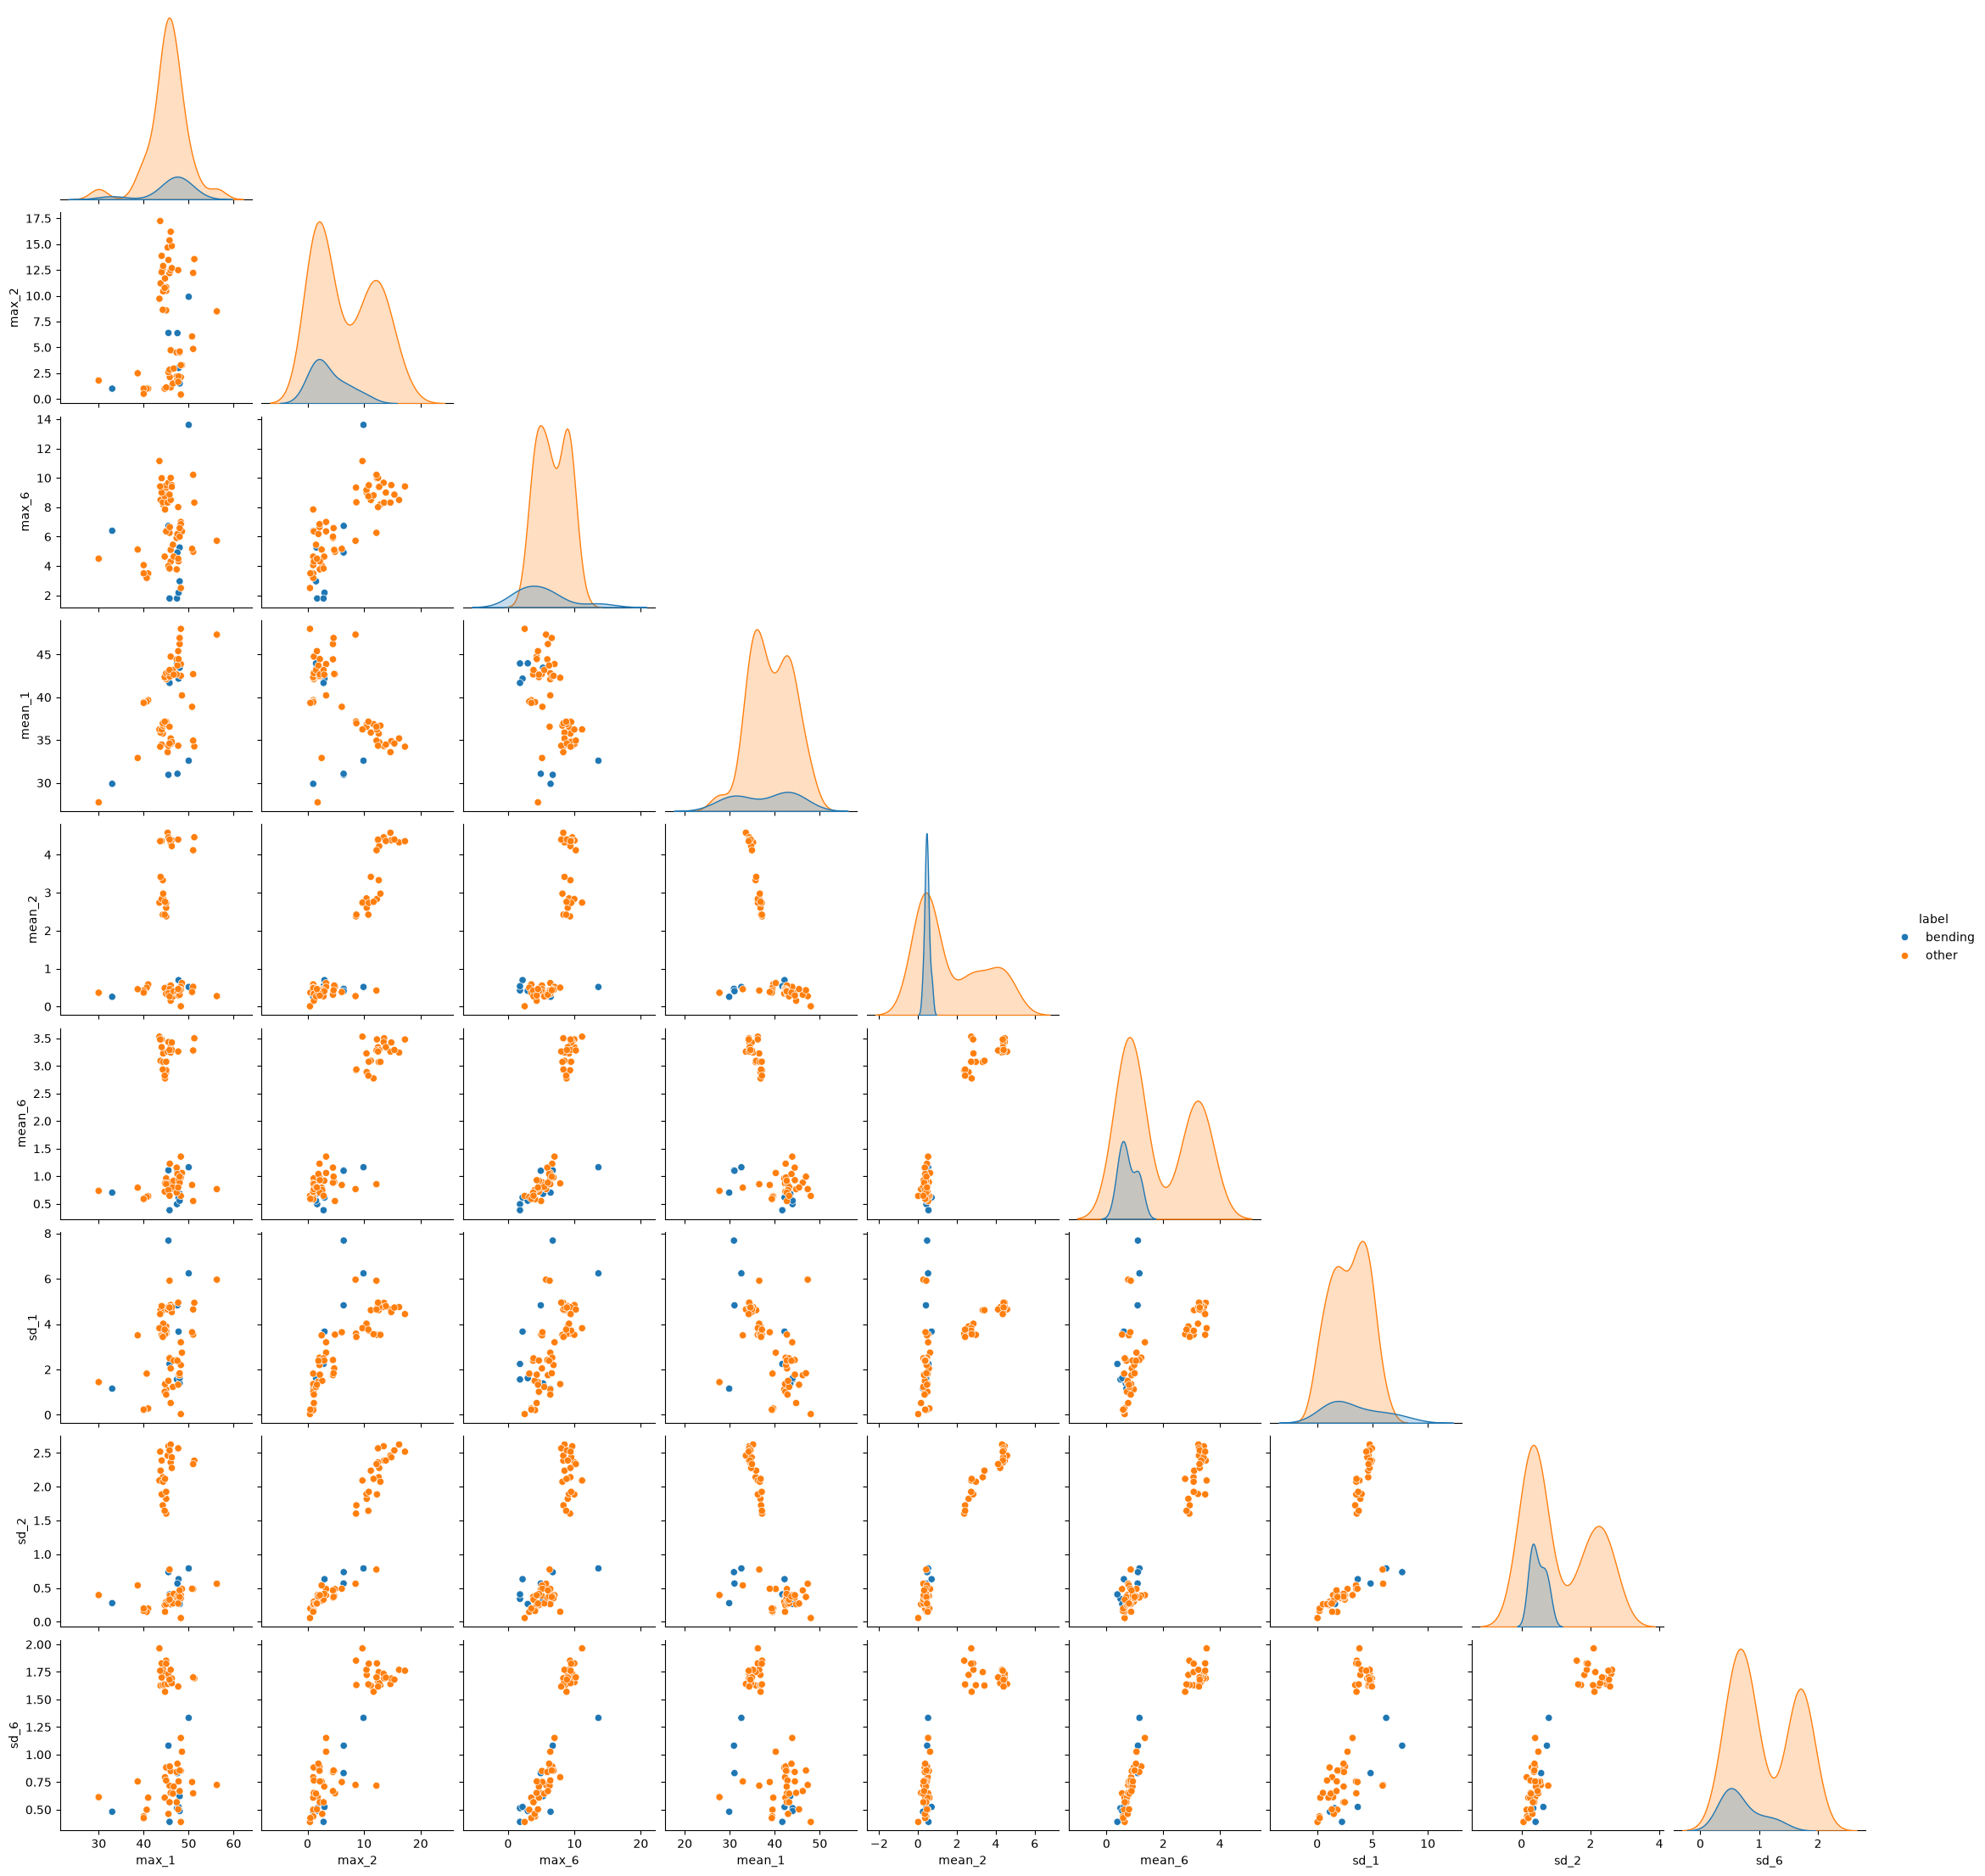

In [11]:
# Create list to pull feature data
stats = ['max', 'mean', 'sd']  # Selected time-domain features
timeseries = [1, 2, 6]  # Selected time series

plot_columns = [f'{stat}_{series}' for stat in stats for series in timeseries]

# Plot data
sns.pairplot(train_df, vars=plot_columns, hue='label', corner=True) # scatterplot of bending vs other activities with 2 colors
plt.show()

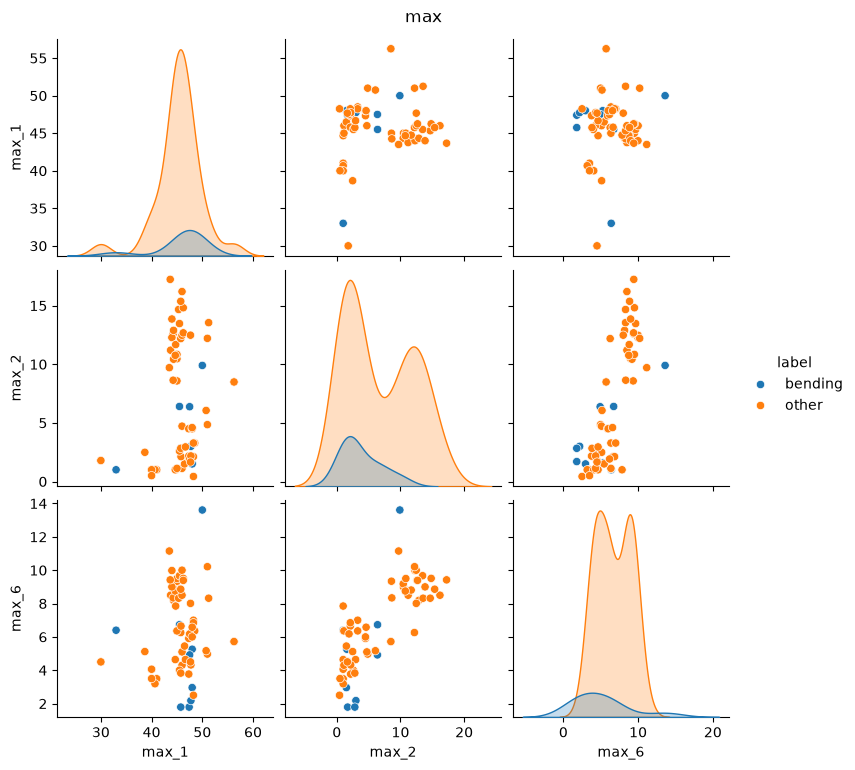

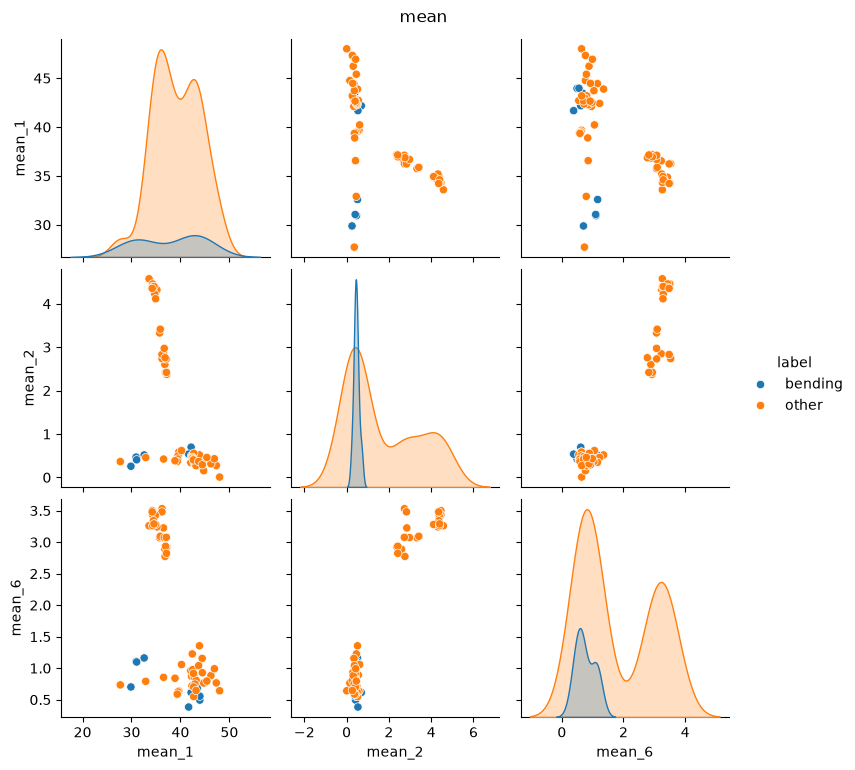

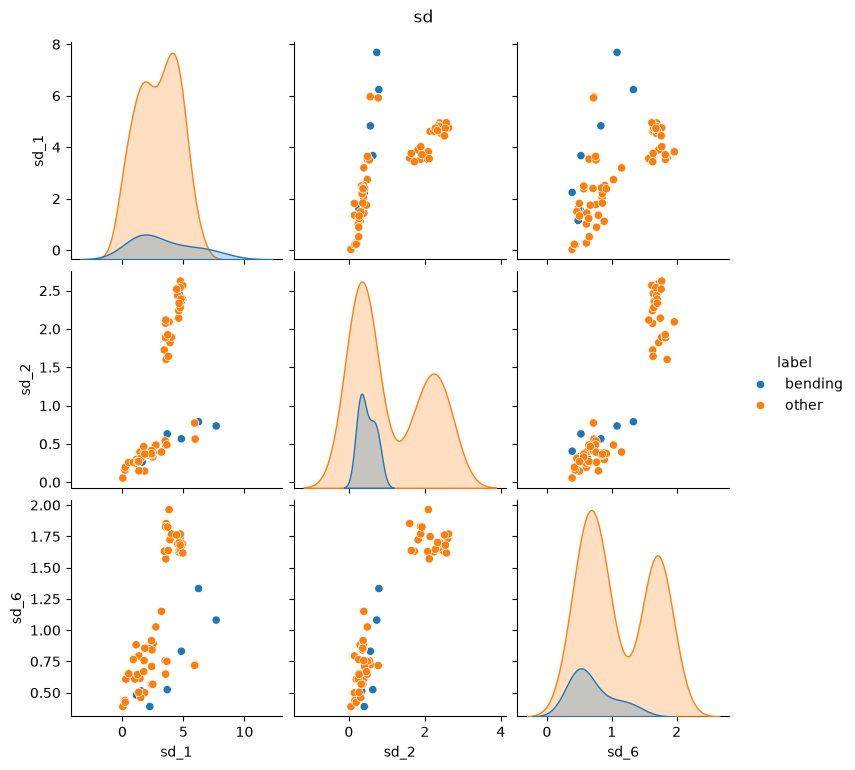

In [12]:
# Separate the scatterplots by variable for easier viewing
timeseries = [1, 2, 6]  # Selected time series
for stat in stats:
    plot_columns = [ f'{stat}_{series}' for series in timeseries ]
    g = sns.pairplot(train_df, vars=plot_columns, hue='label')
    g.figure.suptitle(f'{stat}', y=1.02)     
    plt.show()

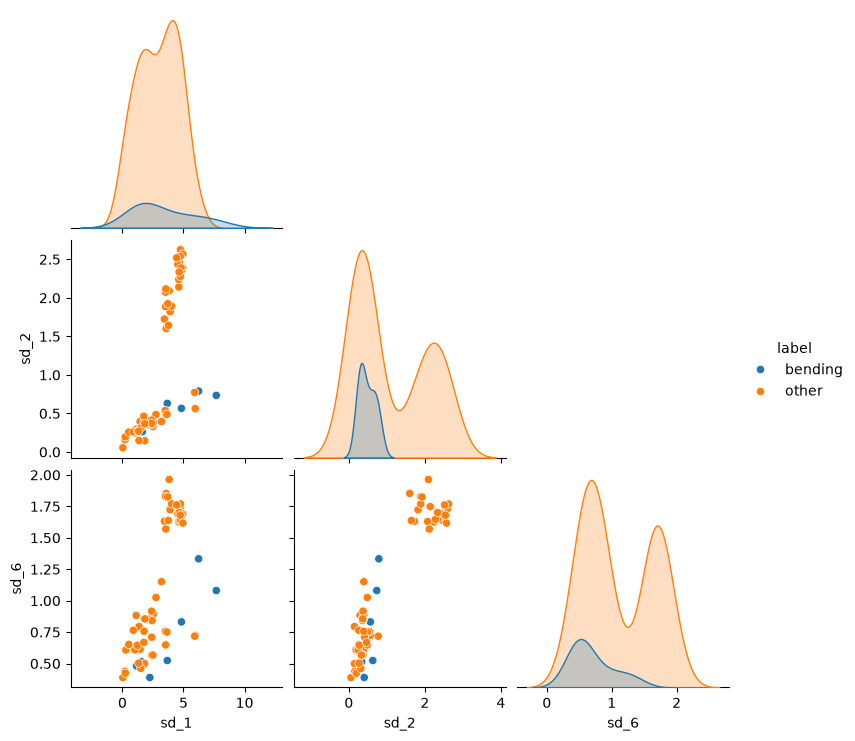

In [13]:
# Testing out with other series 
timeseries = [3,5,6]  # Selected time series

# Plot data
sns.pairplot(train_df, vars=plot_columns, hue='label', corner=True) # scatterplot of bending vs other activities with 2 colors
plt.show()

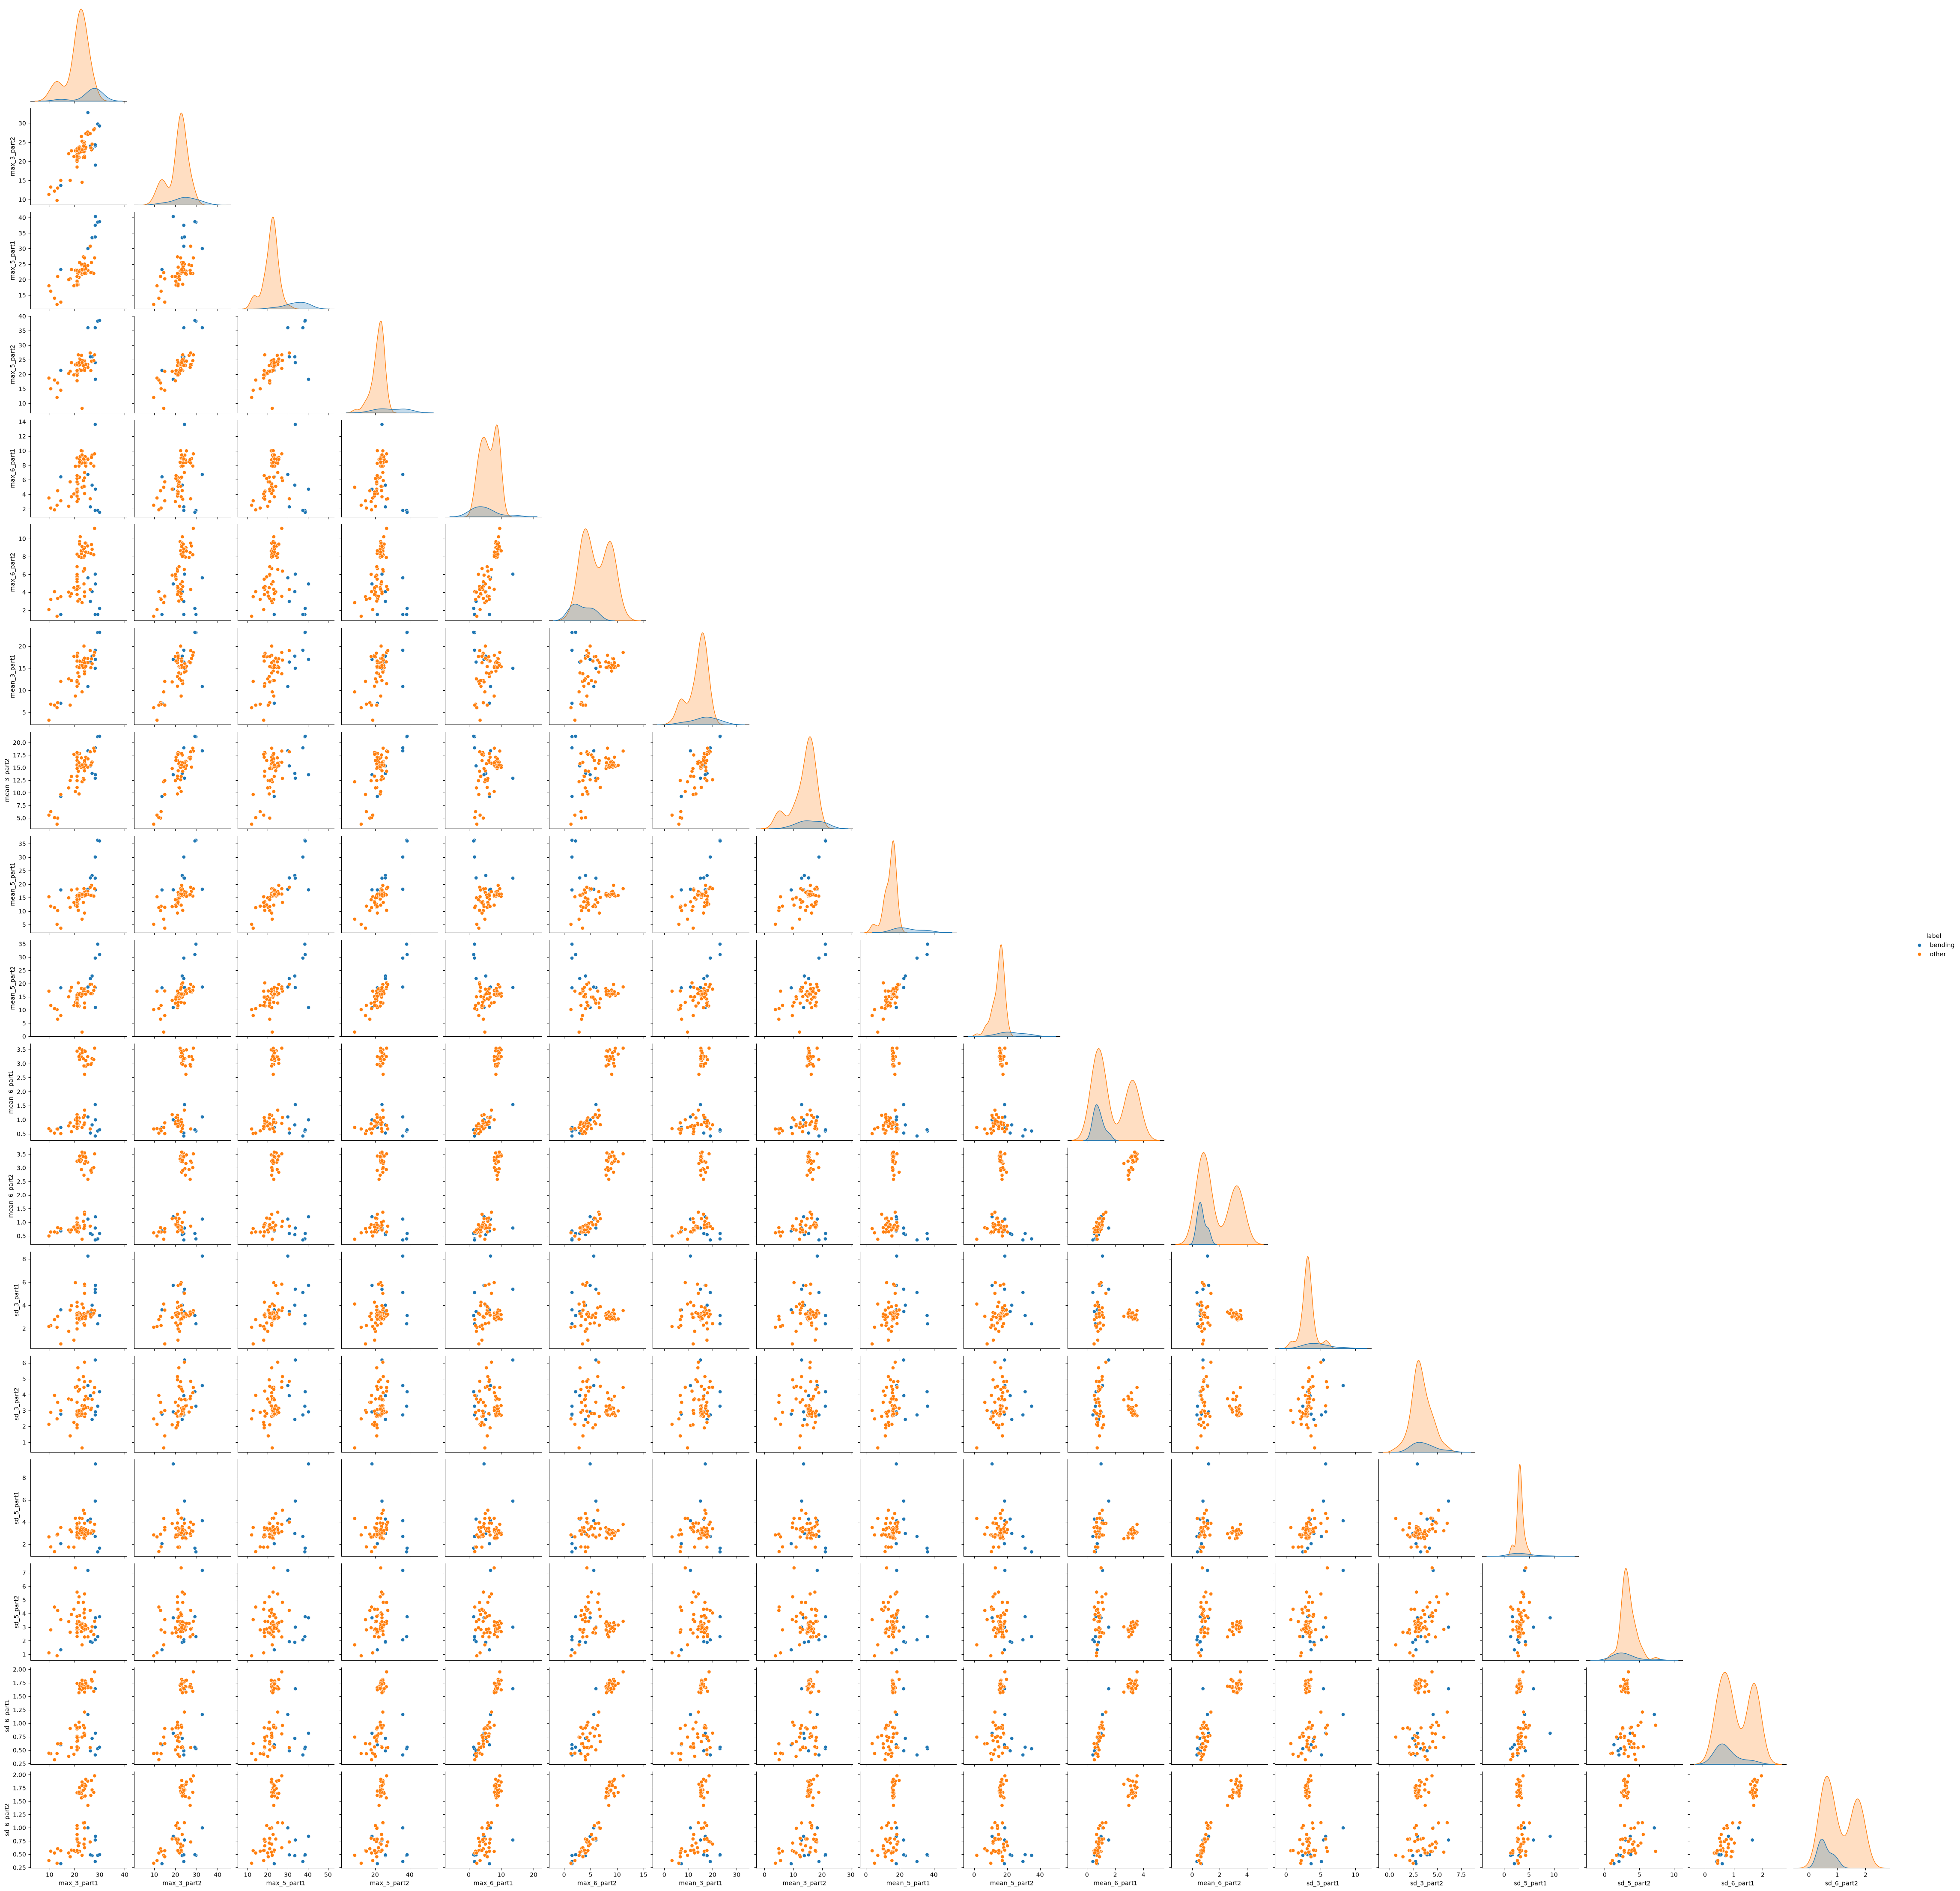

In [14]:
# Split time series training set into two approx equal length 
features_df_2 = build_features_df(2)

# Repeate experiment in 2.a.i
doubled_train_df = features_df_2[features_df_2['split'] == 'train'].copy()

# stratify data by binary classification 'bending' or 'other'
combined_bending = is_activity(doubled_train_df, 'bending') # Combine bending 1 and bending 2 data
doubled_train_df['label'] = np.where(combined_bending, 'bending', 'other') # Split data into binary classification

parts = [1, 2]
split_plot_columns = [f'{stat}_{series}_part{part}' for stat in stats for series in timeseries for part in parts]

# Plot data
sns.pairplot(doubled_train_df, vars=split_plot_columns, hue='label', corner=True) # scatterplot of bending vs other activities with 2 colors
plt.show()

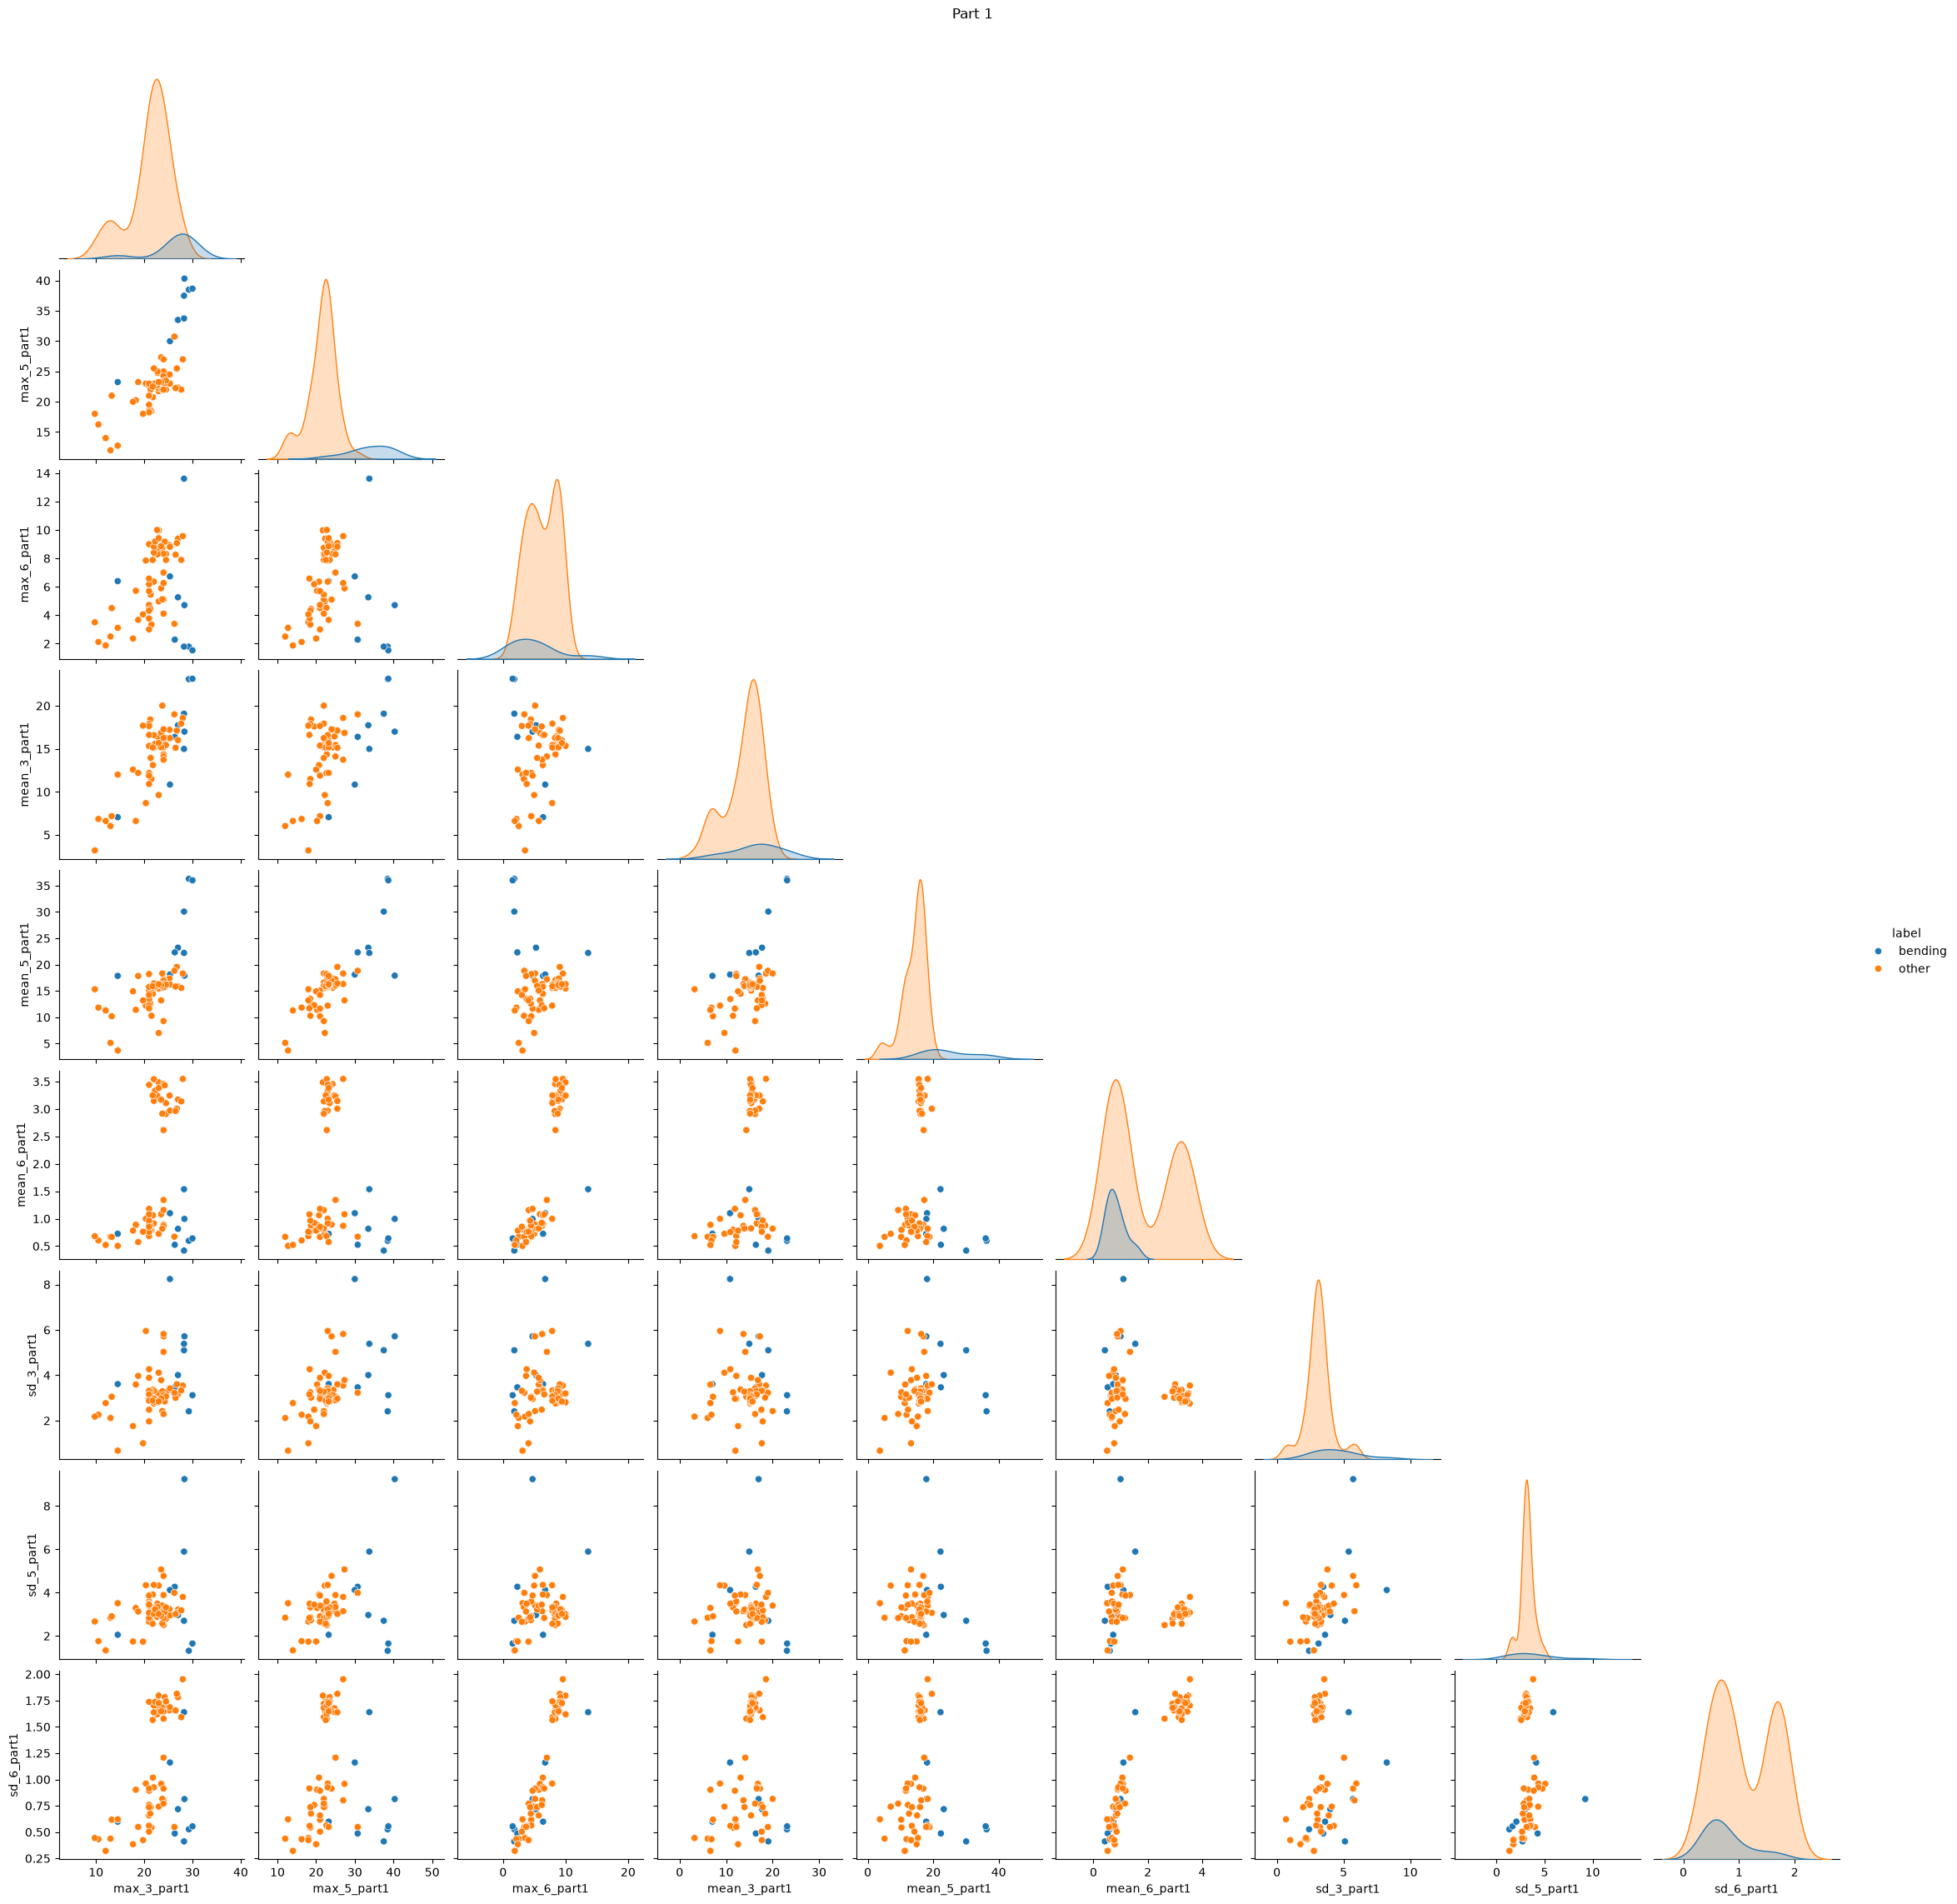

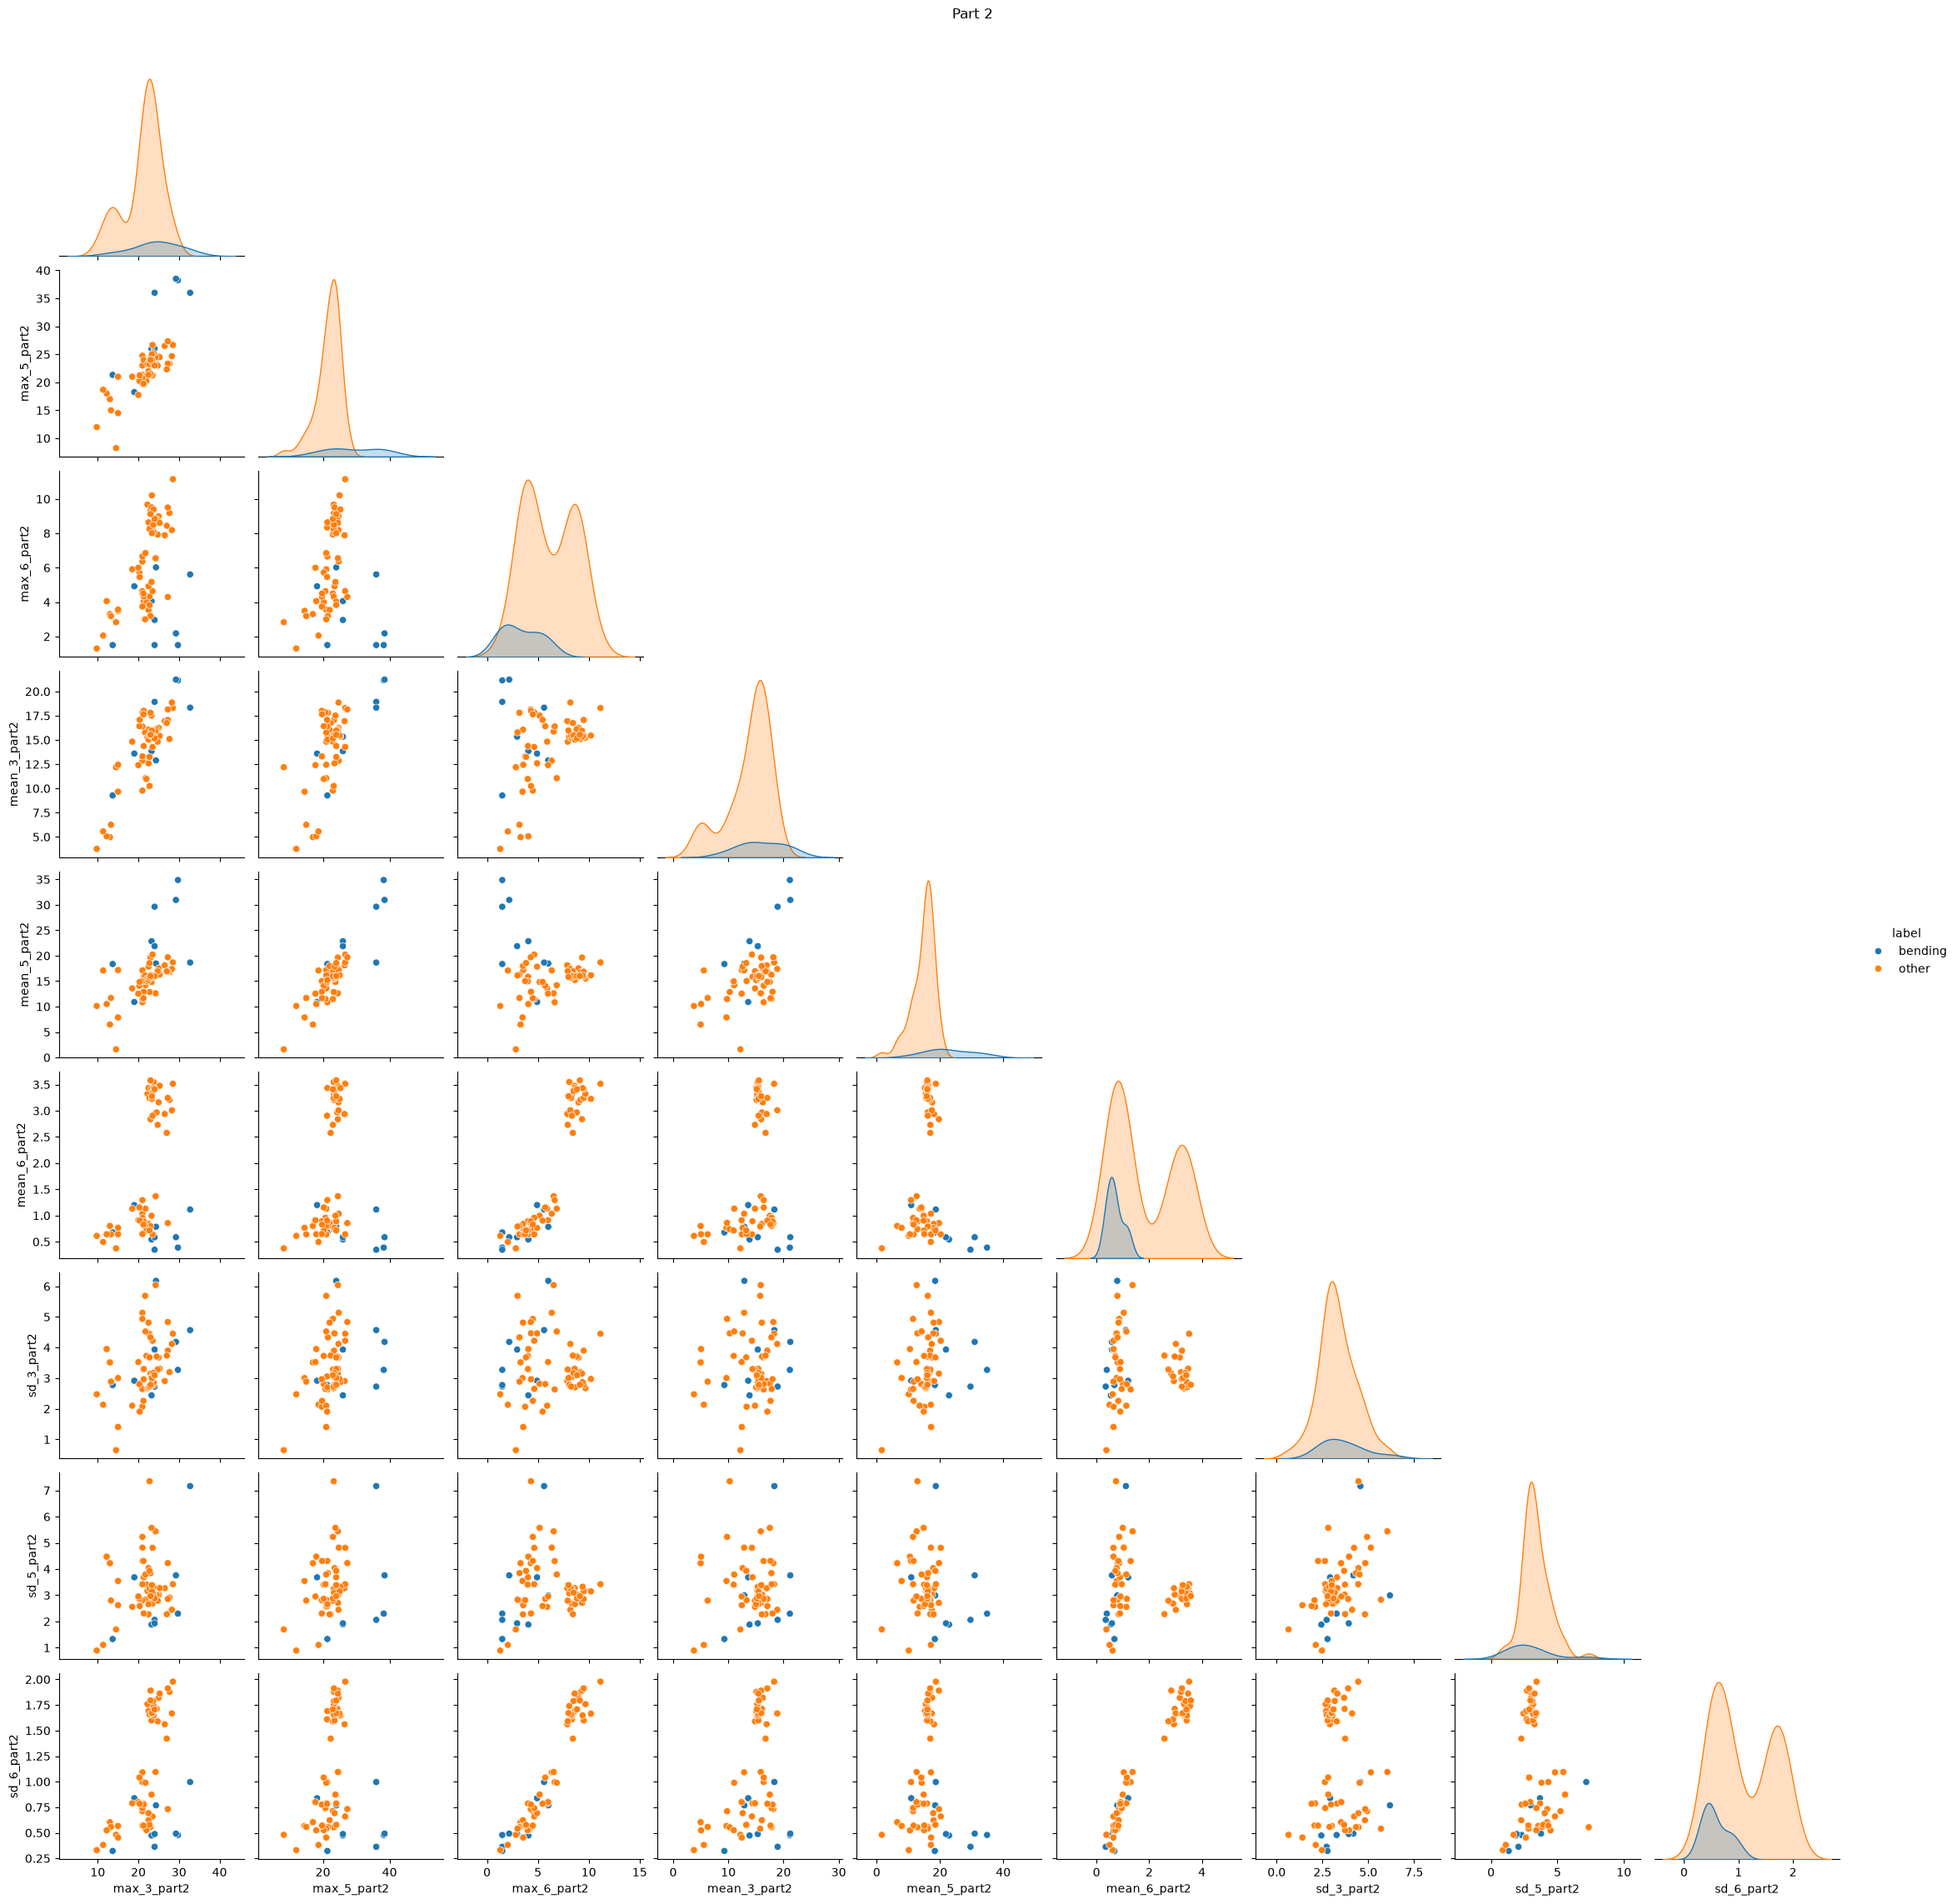

In [15]:
# Splitting the pair plot results into 2 parts for easier viewing
for part in parts:
    columns = [f'{stat}_{series}_part{part}' for stat in stats for series in timeseries]
    g = sns.pairplot(doubled_train_df, vars=columns, hue='label', corner=True)
    g.figure.suptitle(f'Part {part}', y=1.02)
    plt.show()

In [16]:
# Verify function working properly, expected 84
test = get_split_features(load_instance("AReM/bending1/dataset4.csv"), 2)
len(test)

84

Question: Do you see any considerable difference in the results with those of 2(a)i?
Answer: After splitting each of the 6 time series split into two halves (12 total) and running the scatter plot of bending vs non-bending on the features, I did not see a considerable difference in the plots. Overall, across mean, max, and sd, there is not a clear decision boundary between 'bending' and 'not bending' as the bending data overlaps quite consistently with the not bending data. However, it is apparent that "bending" plots overall are lower than the "not bending" plots in variance features (series 2 and 6), showing a ceiling or decision boundary could be drawn to rule OUT 'bending' in certain cases. For example, in series 2 and 6, if sd is >2, it's unlikely to be a 'bending' activity. In terms of what this means for the data, we would not expect splitting bending (combined 1 and 2) across 2 minutes to make a big difference as the activity itself likely involves holding a posture, and we would expect the first half and latter half to have similar results in the sensor data.

#### iii. Time Series Segments

In [17]:
# create 'cv' variable to pass to evaluate_l function for testing multiple l in loop later
cv_l = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)    # Use k=5
""" Using stratified cross validation to retain class distribution across folds """

p_max = 20 # Set a max for p for testing

In [21]:
# Break each time series into l subset (1,2,...20)
# Use logistic regression to solve binary classification, using time-domain features
loop_results = []         # create list to store results from loop

# Create loop to test l from 1, 2, ... 20
for l in range(1, 21):     # 1, 2, ... includes 20
    l_results = evaluate_l(l, stats, cv_l, p_max)          # Saves the current l result first
    best = max(l_results, key=lambda r: r['score'])   # finds best p
    print(f"l={l}: best p={best['p']}, score={best['score']:.3f}")  # Print results
    loop_results.extend(l_results)

loop_results_df = pd.DataFrame(loop_results)

l=1: best p=2, score=0.971
l=2: best p=2, score=0.957
l=3: best p=2, score=0.957
l=4: best p=2, score=0.957
l=5: best p=1, score=0.943
l=6: best p=1, score=0.971
l=7: best p=8, score=0.971
l=8: best p=12, score=0.943
l=9: best p=13, score=0.971
l=10: best p=1, score=0.942
l=11: best p=1, score=0.957
l=12: best p=1, score=0.971
l=13: best p=12, score=0.971
l=14: best p=1, score=0.971
l=15: best p=1, score=0.971
l=16: best p=1, score=0.957
l=17: best p=2, score=0.957
l=18: best p=1, score=0.971
l=19: best p=1, score=0.971
l=20: best p=1, score=0.957


In [42]:
print(loop_results_df)

      l   p     score
0     1   1  0.970330
1     1   2  0.971429
2     1   3  0.941758
3     1   4  0.970330
4     1   5  0.956044
..   ..  ..       ...
393  20  16  0.913187
394  20  17  0.913187
395  20  18  0.913187
396  20  19  0.913187
397  20  20  0.913187

[398 rows x 3 columns]


In [43]:
# Sort the results
loop_results_df.sort_values('score', ascending=False).head(10)

,l,p,score
338,18,1,0.971429
1,1,2,0.971429
170,9,13,0.971429
98,6,1,0.971429
358,19,1,0.971429
218,12,1,0.971429
278,15,1,0.971429
249,13,12,0.971429
258,14,1,0.971429
127,7,10,0.971429


Question: Determine best value of pair (l,p)
Answer: after running the cross validation, there are multiple (l,p) pairs that tie for highest score of 0.9714 (all scores fall between 0.94 and 0.97). I opted to select the simplest model with lowest l and lowest p, which has an l=1 and p=2, since splitting the time series did not notably improve the score.

Question: Explain what the right way and the wrong way are to perform cross-validation in this problem.
Answer: The right way to perform cross-validation is to split the data into folds BEFORE selecting feature selection with RFE to insure the validation set does not leak into the training data. The WRONG way to do this would be to have feature selection occur before folding the dataset, because the selection would use the validation fold's labels, and the CV score comes out too optimistic. My approach was to use a Pipeline (scaling, RFE, model) inside a stratified 5-fold CV (to address imbalance).

#### iv. Confusion Matrix

In [44]:
# Re-fit the model using (l,p) = (1,2) with all training data
selected_l=1
selected_p = 2
X, y = build_xy(selected_l, stats)   # Fit the model using l=1 selected from the previous question
best_pipeline = make_pipeline(selected_p)  # Build pipeline using selected p=2
best_pipeline.fit(X,y)

chosen_features = X.columns[best_pipeline.named_steps['select'].get_support()]  # which features the RFE chose to keep
print("Time-domain features:") 
for f in chosen_features:
    print(relabel_sensors(f))

Time-domain features:
highest | average: ankle A & ankle B (part1)
typical | average: ankle A & ankle B (part1)


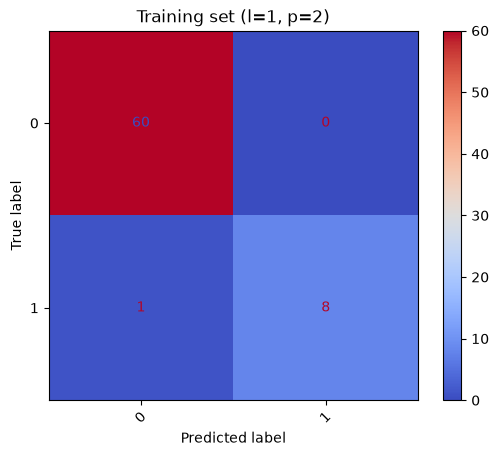

[[60  0]
 [ 1  8]]


In [45]:
# Show confusion matrix
cm_train = plot_confusion_matrix(best_pipeline, X, y, 'Training set (l=1, p=2)')

print(cm_train)

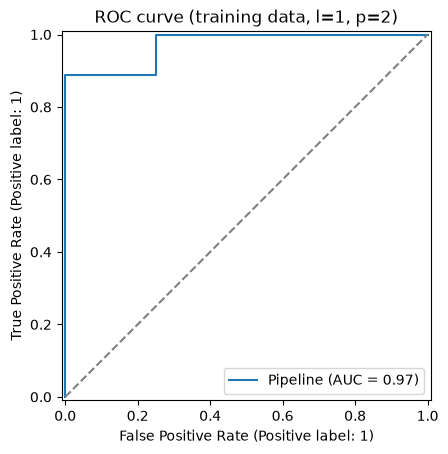

AUC: 0.972


In [46]:
# Show the ROC and AUC for classifier on train data
RocCurveDisplay.from_estimator(best_pipeline, X, y)
plt.title('ROC curve (training data, l=1, p=2)')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')   # reference line showing p = .5
plt.show()

auc = roc_auc_score(y, best_pipeline.predict_proba(X)[:, 1])
print(f'AUC: {auc:.3f}')

In [47]:
# Report the parameters of your logistic regression features as well as p-values associated
X_chosen = X[chosen_features]
X_scaled = StandardScaler().fit_transform(X_chosen)        # Scale in same as pipeline
X_sm = sm.add_constant(pd.DataFrame(X_scaled, columns=chosen_features, index=X.index))

logit = sm.Logit(y, X_sm).fit()
print(logit.summary())

Optimization terminated successfully.
         Current function value: 0.086130
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:               activity   No. Observations:                   69
Model:                          Logit   Df Residuals:                       66
Method:                           MLE   Df Model:                            2
Date:                Tue, 20 Oct 2026   Pseudo R-squ.:                  0.7776
Time:                        21:44:46   Log-Likelihood:                -5.9430
converged:                       True   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 9.499e-10
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -4.7154      1.465     -3.218      0.001      -7.587      -1.843
max_5_part1      2.340

2.1.4.iv. Further explantion:
Feature selection: The two features selected from the RFE were 'max_5_part1' (the highest of ankle A to ankle B signal) and 'mean_5_part1' (the average of the ankle A to ankle B signal). In this case 'part1' is the whole recording l=1 and based on the optimal (l,p) pair, no splitting was needed. Since the feature 'max_5_part1' has a lower p-value than feature 'mean_5_part1', we can be more confident it has a real effect on predicting Y = 1, or activity = bending.

Coefficient: The β (constant) is -4.7154 with a p value of .001. The β for feature max_5_part1 is 2.3404 with p value .006, meaning it is statistically significant at the .05 level (p<.05), while the β for mean_5_part 1 is 3.117 with a higher p value of .109 meaning it is not statistically significant at .05 level (p> .05). Both β are positive, which indicates a stronger ankle to ankle signal increases the predicted probability of 'bending' as activity. Note these coefficients are calculated on standardized features.

Note: The "quasi-separation" warning shows .17 observations perfectly predicted (about 12 out of 69), likely due to the training data. These two features separate from bending and not bending rows perfectly, so the model is 100% certain on them, which results in making the coefficient estimates and p-values less stable. 

Confusion matrix: The confusion matrix results show [[60, 0], [1, 8]] (60 true negatives, 0 false positives, 1 false negative, 8 true positives) or 1 bending misclassifed as other (type II error) and 0 non-bending misclassifed as bending (type I error). Accuracy = 68/69 (on training data) = 98.6%.

ROC: The ROC curve rises steeply and hugs the top-left corner, well above the dashed random-guess line.

AUC: The AUC result was .972, which means between two randomly selected values, 97.2% of the time the model will give the bending one a higher probability of being predicted 'bending'.

#### v. Test Classifier

In [48]:
# Test classifier on test set using same l (l=1) as training
X_test, y_test = build_xy(selected_l, stats, 'test')

In [49]:
# Check test data is still in tact
print(X_test.shape, y_test.sum())

(19, 18) 4


In [50]:
# Compare test accuracy to cross validation accuracy obtained previously
test_accuracy = best_pipeline.score(X_test, y_test)

cv_accuracy = loop_results_df.loc[
    (loop_results_df['l'] == selected_l) & (loop_results_df['p'] == selected_p),
    'score'
].iloc[0]

print(f'Test accuracy: {test_accuracy:.3f}')
print(f'CV accuracy:   {cv_accuracy:.3f}')

Test accuracy: 0.947
CV accuracy:   0.971


Result: The test accuracy is .947, slightly lower than the cross validation accuracy (.971), which is expected. This indicates one misclassification (18/19) and shows the cv score was a fairly strong estimate of accuracy on the unseen data. 

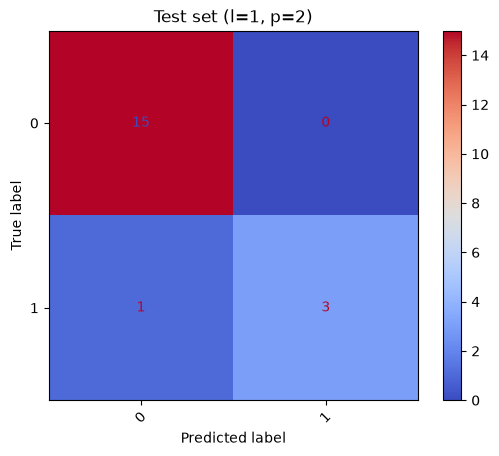

[[15  0]
 [ 1  3]]


In [51]:
# Show confusion matrix for test set
cm_test = plot_confusion_matrix(best_pipeline, X_test, y_test, 'Test set (l=1, p=2)')
print(cm_test)

The confusion matrix shows 15 true negatives (not bending correctly labeled), 0 false positives (not bending labeled as bending), 1 false negative (bending labeled as other), and 3 true positives (bending labeled bending)

#### vi. Separation

Answer: The classes are not fully separated, so the instability is mild. According to the model it is quasi-separated, with some overlap (about 17% of rows are perfectly separated, but the rest overlap), but the model still converged and predicted finite coefficients for the selected features. There is some instability (mean_5's standard error is larger than others at 1.95) with a CI that includes 0. This could be in part due to the max_5 and mean_5 moving together as these features are not completely independent.

#### vii. Imbalance

Answer: Yes, the class imbalance is present in the training data. Out of 69 instances, there are only 9 cases of 'bending' vs 60 cases of 'other' (not bending). As visible in the test and train confusion matrices, in both cases there were no predicted classes of bending that were actually other (false positive), showing a high test accuracy rate of (94.7%), but in both test and train cases, there were actual positive cases of 'bending' missed (classified as 'other'). In the test, 1 out of 4 actual bending cases were missed (25%), which puts the TPR at 75% (out of the total cases of 'bending' it only caught 75% of them). High accuracy with lower recall is a sign of class imbalance.

Selected p = 2
(18, 18) 9
Index(['max_5_part1', 'mean_6_part1'], dtype='str')
Before: [0.04721794]
After:  [-1.84990205]


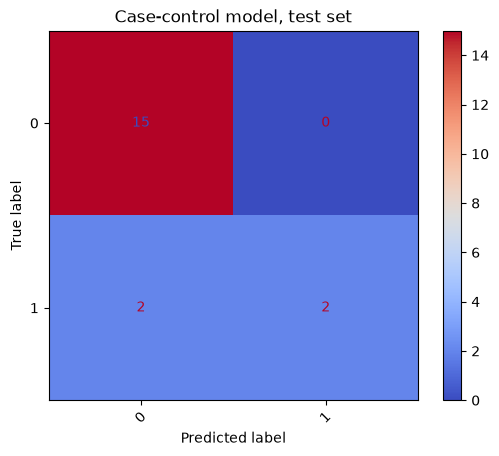

ROC:


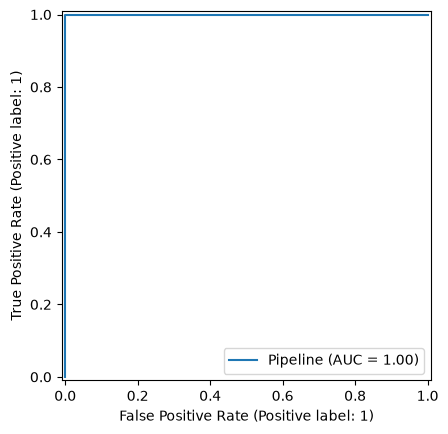

AUC: 1.000


In [52]:
# If yes, build a logistic regression model based on case-control sampling
X_casecontrol, y_casecontrol = case_control_sample(X, y)   # calls the case_control_sample function with all 9 bending and 9 'other' random samples
print(f'Selected p = {selected_p}')   # check to make sure variable is still in tact
cc_pipeline = make_pipeline(selected_p)  # runs pipeline with selected p from earlier
cc_pipeline.fit(X_casecontrol, y_casecontrol)

# Test to check code is working (expected (18,18), 9)
print(X_casecontrol.shape, y_casecontrol.sum())

# Check cc features
cc_features = X.columns[cc_pipeline.named_steps['select'].get_support()]
print(cc_features)

# Adjust the parameters
pi_true = y.mean()               # adjust to 9 out of 69 (actual bending instances)
pi_sample = y_casecontrol.mean() # case control trained on 50/50

model = cc_pipeline.named_steps['model']
print('Before:', model.intercept_)
model.intercept_ += np.log(pi_true / (1 - pi_true)) - np.log(pi_sample / (1 - pi_sample))
print('After: ', model.intercept_)

# Plot confusion matrix
plot_confusion_matrix(cc_pipeline, X_test, y_test, 'Case-control model, test set')

# Show ROC
print("ROC:")
RocCurveDisplay.from_estimator(cc_pipeline, X_test, y_test)
plt.show()

# Show AUC
auc_test = roc_auc_score(y_test, cc_pipeline.predict_proba(X_test)[:, 1])
print(f'AUC: {auc_test:.3f}')

Analysis: The case-control model’s test AUC is 1.0, so it ranks every bending instance above every non-bending one. But at the default 50/50 threshold it only catches 2 of 4 (TPR 50%), because the intercept adjustment lowers the predicted probabilities. A lower threshold would catch all of them. (With only 4 bending test cases, these numbers are fragile.)

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [53]:
# Repeat 2(a)iii with L1 penalized logistic regression
c_values = np.logspace(-2, 2, 20)  # 20 values from 0.01 to 100, evenly spaced on a log scale

In [54]:
print(cv_l)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [55]:
# Instead of p-values for variable selection, use l1 regularization
cloop_results = []         # create list to store results from loop

# Create loop to test l from 1, 2, ... 20
for l in range(1, 21):     # 1, 2, ... includes 20
    l_l1_results = evaluate_l_l1(l, stats, cv_l, c_values)          # Saves the current l result first
    best = max(l_l1_results, key=lambda r: r['score'])   # finds best c
    print(f"l={l}: best c={best['C']:.3f}, score={best['score']:.3f}")  # Print results
    cloop_results.extend(l_l1_results)

cloop_results_df = pd.DataFrame(cloop_results)

l=1: best c=3.360, score=0.971
l=2: best c=0.298, score=0.957
l=3: best c=0.298, score=0.971
l=4: best c=0.298, score=0.957
l=5: best c=0.483, score=0.927
l=6: best c=0.298, score=0.957
l=7: best c=0.483, score=0.927
l=8: best c=61.585, score=0.943
l=9: best c=0.785, score=0.927
l=10: best c=3.360, score=0.957
l=11: best c=8.859, score=0.957
l=12: best c=3.360, score=0.971
l=13: best c=0.183, score=0.943
l=14: best c=0.483, score=0.971
l=15: best c=0.298, score=0.957
l=16: best c=0.483, score=0.929
l=17: best c=0.785, score=0.957
l=18: best c=3.360, score=0.971
l=19: best c=0.785, score=0.971
l=20: best c=5.456, score=0.971


In [63]:
# Sort results 
best_score = cloop_results_df['score'].max()  # Find top score from results 
ties = cloop_results_df[cloop_results_df['score'] == best_score]  # include all tied scores
ties.sort_values(['l', 'C']).head() # sort by lowest l-value, then c

,l,C,score
12,1,3.359818,0.971429
13,1,5.455595,0.971429
47,3,0.297635,0.971429
48,3,0.483293,0.971429
232,12,3.359818,0.971429


In [64]:
# Assign best l and c as variables
best_row = ties.sort_values(['l', 'C']).iloc[0]
best_l1_l, best_c = int(best_row['l']), best_row['C']

print(f"Best l, c pair = ({best_l1_l}, {best_c:.3f})")

Best l, c pair = (1, 3.360)


In [65]:
# Test to see l1
test_pipe = make_l1_pipeline(0.1).fit(X, y)
print((test_pipe.named_steps['model'].coef_ == 0).sum(), 'of', X.shape[1], 'coefficients are zero')

17 of 18 coefficients are zero


In [66]:
# Refit, test, L1 model
X_l1, y_l1 = build_xy(best_l1_l, stats)
X_l1_test, y_l1_test = build_xy(best_l1_l, stats, 'test')  # Use test data to check accuracy

l1_best = make_l1_pipeline(best_c).fit(X_l1, y_l1)  # Re-fit model with training data

betas = l1_best.named_steps['model'].coef_[0]
kept = X_l1.columns[betas != 0]
print(f'L1 kept {len(kept)} of {X_l1.shape[1]} features:')
for f in kept:
    print('  ', relabel_sensors(f))

print(f"L1 test accuracy:  {l1_best.score(X_l1_test, y_l1_test):.3f}")
print(f"RFE test accuracy: {test_accuracy:.3f}")

L1 kept 7 of 18 features:
   highest | variance: chest & ankle A (part1)
   highest | average: ankle A & ankle B (part1)
   typical | average: chest & ankle A (part1)
   typical | average: chest & ankle B (part1)
   typical | average: ankle A & ankle B (part1)
   variation in | average: ankle A & ankle B (part1)
   variation in | variance: ankle A & ankle B (part1)
L1 test accuracy:  1.000
RFE test accuracy: 0.947


#### ii. Comparison

Answer: The L1 penalized logistic regression model performed slightly better than the RFE original model, correctly classifying all of the test instances (4 out of 19 as 'bending', rest as 'other'), while the earlier model correctly identified 18/19 (.947). Both had the same CV accuracy at 0.971, which shows the gap only appears on the test set. The L1 model selected 7 features out of 18, and does so within the model, making it easier to use than the RFE, which takes more compute to loop over p. However, the RFE model selected 2 features (p=2), making the model itself simpler, only taking 2 predictors. Both models kept the ankle-to-ankle average features, indicating a strong predictive weight for this feature, in other words that the ankle to ankle signal is an informative feature to predicting whether the subject is bending or not bending.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [67]:
# Test updated build_xy function (passing multinomial parameter)
X_mn, y_mn = build_xy(1, stats, binary=False)
y_mn.unique()

<StringArray>
['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Length: 7, dtype: str

In [76]:
# Build new cv for multinomial with 4 folds to address error 'least populated class has only 4 members'
cv_mn = StratifiedKFold(n_splits=4, shuffle=True, random_state=42)

In [69]:
# Ignore warnings to clean up results visiblity
import warnings
from sklearn.exceptions import ConvergenceWarning 
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Build an l1-penalized multinomial model to classify all activities in training set
c_values = np.logspace(-2, 2, 20)  
mnloop_results = []         # create list to store results from loop

# Create loop to test l from 1, 2, ... 20
for l in range(1, 21):     # 1, 2, ... includes 20
    # runs evaluate_l_l1 with multinomial parameters (solver=saga)
    l_l1_results = evaluate_l_l1(l, stats, cv_mn, c_values, binary=False)          # Saves the current l result first
    best = max(l_l1_results, key=lambda r: r['score'])   # finds best c
    print(f"l={l}: best c={best['C']:.3f}, score={best['score']:.3f}")  # Print results
    mnloop_results.extend(l_l1_results)

mnloop_results_df = pd.DataFrame(mnloop_results)

l=1: best c=8.859, score=0.913
l=2: best c=100.000, score=0.913
l=3: best c=61.585, score=0.855
l=4: best c=100.000, score=0.842
l=5: best c=61.585, score=0.855
l=6: best c=100.000, score=0.869
l=7: best c=100.000, score=0.812
l=8: best c=0.483, score=0.810
l=9: best c=100.000, score=0.842
l=10: best c=2.069, score=0.797
l=11: best c=2.069, score=0.797
l=12: best c=1.274, score=0.825
l=13: best c=8.859, score=0.783
l=14: best c=2.069, score=0.811
l=15: best c=3.360, score=0.840
l=16: best c=0.785, score=0.795
l=17: best c=0.298, score=0.841
l=18: best c=5.456, score=0.855
l=19: best c=1.274, score=0.825
l=20: best c=14.384, score=0.869


Note: In this case I interpreted "all activities" as separating bending1 and bending2 as 2 separate activites, resulting in 7 separate classes

In [70]:
# Sort results 
best_score = mnloop_results_df['score'].max()  # Find top score from results 
ties = mnloop_results_df[mnloop_results_df['score'] == best_score]  # include all tied scores
ties.sort_values(['l', 'C']).head() # sort by lowest l-value, then c

,l,C,score
14,1,8.858668,0.913399
39,2,100.000000,0.913399


In [71]:
# Get best cv before refitting model
best_row = ties.sort_values(['l', 'C']).iloc[0]
best_mn_l = int(best_row['l'])
best_mn_c = best_row['C']

In [72]:
# Refit the model with the training data
X_mn, y_mn = build_xy(best_mn_l, stats, binary=False)
X_mn_test, y_mn_test = build_xy(best_mn_l, stats, 'test', binary=False)  # Use test data to check accuracy

mn_best = make_l1_pipeline(best_mn_c, solver='saga').fit(X_mn, y_mn)  # Re-fit model with training data

betas = mn_best.named_steps['model'].coef_
kept = X_mn.columns[(betas != 0).any(axis=0)]
print(f'L1 kept {len(kept)} of {X_mn.shape[1]} features:')
for f in kept:
    print('  ', relabel_sensors(f))

print(f"L1 test accuracy:  {mn_best.score(X_mn_test, y_mn_test):.3f}")
print(f"Test error: {1 - mn_best.score(X_mn_test, y_mn_test):.3f}")

L1 kept 15 of 18 features:
   highest | average: chest & ankle A (part1)
   highest | variance: chest & ankle A (part1)
   highest | average: chest & ankle B (part1)
   highest | variance: chest & ankle B (part1)
   highest | average: ankle A & ankle B (part1)
   highest | variance: ankle A & ankle B (part1)
   typical | average: chest & ankle A (part1)
   typical | variance: chest & ankle A (part1)
   typical | average: chest & ankle B (part1)
   typical | average: ankle A & ankle B (part1)
   variation in | average: chest & ankle A (part1)
   variation in | average: chest & ankle B (part1)
   variation in | variance: chest & ankle B (part1)
   variation in | average: ankle A & ankle B (part1)
   variation in | variance: ankle A & ankle B (part1)
L1 test accuracy:  0.895
Test error: 0.105


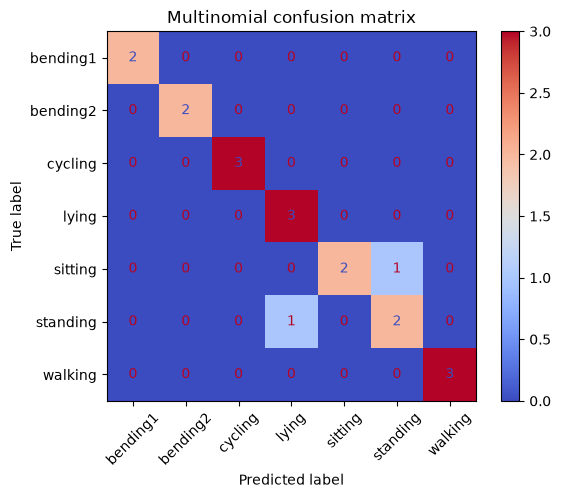

array([[2, 0, 0, 0, 0, 0, 0],
       [0, 2, 0, 0, 0, 0, 0],
       [0, 0, 3, 0, 0, 0, 0],
       [0, 0, 0, 3, 0, 0, 0],
       [0, 0, 0, 0, 2, 1, 0],
       [0, 0, 0, 1, 0, 2, 0],
       [0, 0, 0, 0, 0, 0, 3]])

In [73]:
# Show how confusion matrices and ROC curves are defined for multiclass classification
plot_confusion_matrix(mn_best, X_mn_test, y_mn_test, 'Multinomial confusion matrix') # Pass the mn model from above to confusion matrix

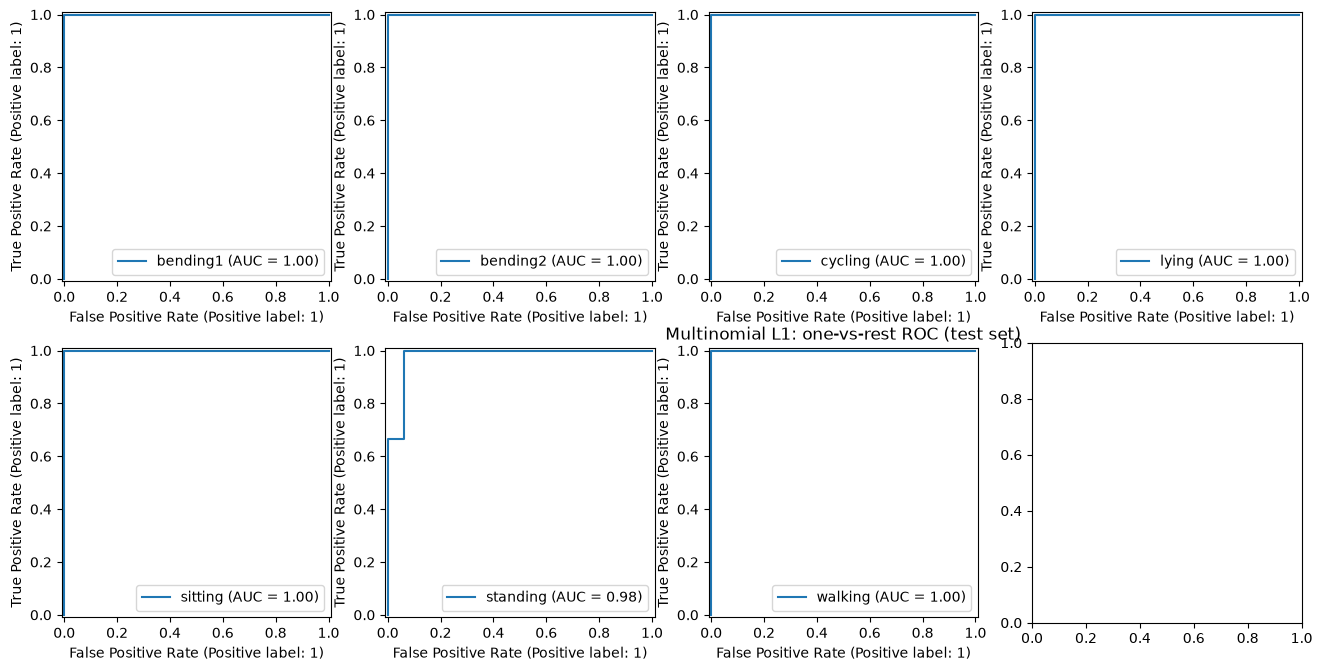

In [75]:
# Show ROC curve
p_activities = mn_best.predict_proba(X_mn_test)   # 19 rows × 7 columns, one column per activity
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (i, activity) in zip(axes.flat, enumerate(mn_best.classes_)):  # Display all ROC curves separately
    y_true = (y_mn_test == activity)
    y_score = p_activities[:, i]
    RocCurveDisplay.from_predictions(y_true, y_score, name=activity, ax=ax)

ax.set_title('Multinomial L1: one-vs-rest ROC (test set)')  # Add title label
plt.show()

Answer: A multi-class confusion matrix and Multiclass ROC curve are extensions of binary classification metrics used to evaluate machine learning models with 3 or more classes. To adapt them from binary to multi-class, the typical structure includes rows representing Actual/True classes, columns representing Predicted classes, Diagonal elements represent correct predictions (True positives for each class) and Off-diagonal elements represent misclassifications (errors where one class mistaken for another).

To calculate metrics like Precision, Recall, and F-1 score for each class, that class (example: Class A) is treated as "positive" while all other classes combined are "negative". 

One common approach to show ROC curve is the one-vs-rest (shown above) approach, where you there are N number of curves for N classes.

#### ii. Naive Bayes

In [92]:
# Use Naive Bayes classifier
nbloop_results = []         # create list to store results from loop

# Use Gaussian priors to run loop
for l in range(1, 21):     # 1, 2, ... includes 20
    nb_l_results = evaluate_l_nb(l, stats, cv_mn, GaussianNB())       # Run l loop using Gaussian model       
    nbloop_results.append(nb_l_results)
    
nbloop_results_df = pd.DataFrame(nbloop_results)      # Converts to dataframe

In [93]:
# Check results
nbloop_results_df.head()

,l,score
0,1,0.899510
1,2,0.870098
2,3,0.840686
3,4,0.883987
4,5,0.812908


In [99]:
# Sort the results
nb_best_score = nbloop_results_df['score'].max()  # Find top score from results 
nb_ties = nbloop_results_df[nbloop_results_df['score'] == nb_best_score]  # include all tied scores
nb_best_row = nb_ties.sort_values('l').iloc[0]

nb_best_l = int(nb_best_row['l'])
nb_best_cv = nb_best_row['score']

print(f"Best l: {nb_best_l}")
print(f"Best cv: {nb_best_cv:.3f}")

Best l: 1
Best cv: 0.900


In [103]:
# Refit on training data
X_nb, y_nb = build_xy(nb_best_l, stats, binary=False)
X_nb_test, y_nb_test = build_xy(nb_best_l, stats, 'test', binary=False )  # Use test data to check accuracy

gnb_best = GaussianNB().fit(X_nb, y_nb)   # Refit GaussianNB model 

# Run model on test data
print(f"Test error: {1 - gnb_best.score(X_nb_test, y_nb_test):.3f}")

Test error: 0.105


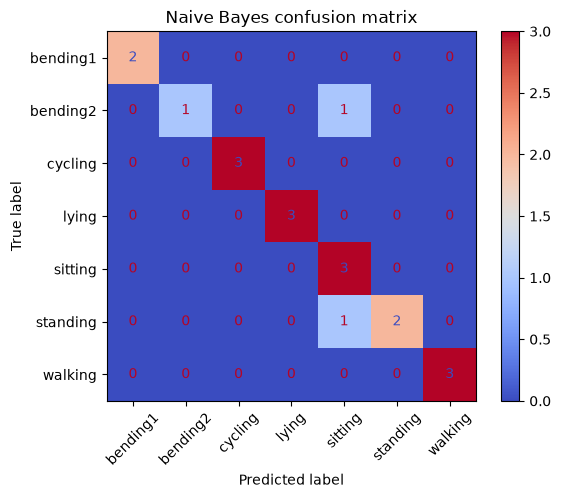

array([[2, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0],
       [0, 0, 3, 0, 0, 0, 0],
       [0, 0, 0, 3, 0, 0, 0],
       [0, 0, 0, 0, 3, 0, 0],
       [0, 0, 0, 0, 1, 2, 0],
       [0, 0, 0, 0, 0, 0, 3]])

In [105]:
# Plot confusion matrix for NB Model
plot_confusion_matrix(gnb_best, X_nb_test, y_nb_test, 'Naive Bayes confusion matrix')

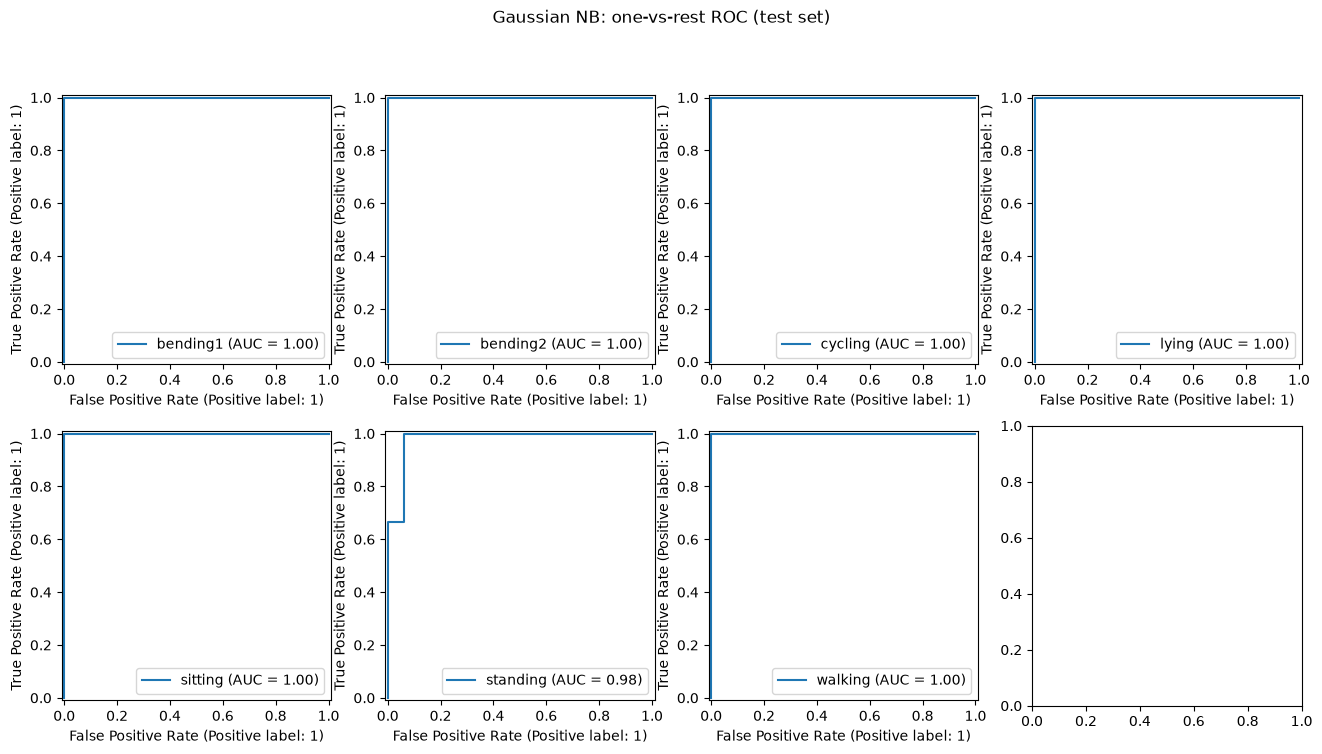

In [121]:
# Show ROC Curve
nb_p_activities = gnb_best.predict_proba(X_nb_test)   
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (i, activity) in zip(axes.flat, enumerate(gnb_best.classes_)):  # Display all ROC curves separately
    nb_y_true = (y_nb_test == activity)
    nb_y_score = nb_p_activities[:, i]
    RocCurveDisplay.from_predictions(nb_y_true, nb_y_score, name=activity, ax=ax)

fig.suptitle('Gaussian NB: one-vs-rest ROC (test set)')  # Add title label
plt.show()

In [112]:
# Use Multinomial Priors
mnb_pipe = make_mnb_pipeline()

mnbloop_results = []

# Run loop for best l with multinomial pipeline
for l in range(1, 21):
    mnb_l_results = evaluate_l_nb(l, stats, cv_mn, mnb_pipe)
    mnbloop_results.append(mnb_l_results)

mnbloop_results_df = pd.DataFrame(mnbloop_results)

In [113]:
# Sort results
mnb_best_score = mnbloop_results_df['score'].max()  # Find top score from results 
mnb_ties = mnbloop_results_df[mnbloop_results_df['score'] == mnb_best_score]  # include all tied scores
mnb_best_row = mnb_ties.sort_values('l').iloc[0]

mnb_best_l = int(mnb_best_row['l'])
mnb_best_cv = mnb_best_row['score']

print(f"Best l: {mnb_best_l}")
print(f"Best cv: {mnb_best_cv:.3f}")

Best l: 3
Best cv: 0.811


In [114]:
# Refit on training data
X_mnb, y_mnb = build_xy(mnb_best_l, stats, binary=False)
X_mnb_test, y_mnb_test = build_xy(mnb_best_l, stats, 'test', binary=False )  # Use test data to check accuracy

mnb_best = make_mnb_pipeline().fit(X_mnb, y_mnb)   # Refit using Multinomial model 

# Run model on test data
print(f"Test error: {1 - mnb_best.score(X_mnb_test, y_mnb_test):.3f}")

Test error: 0.211


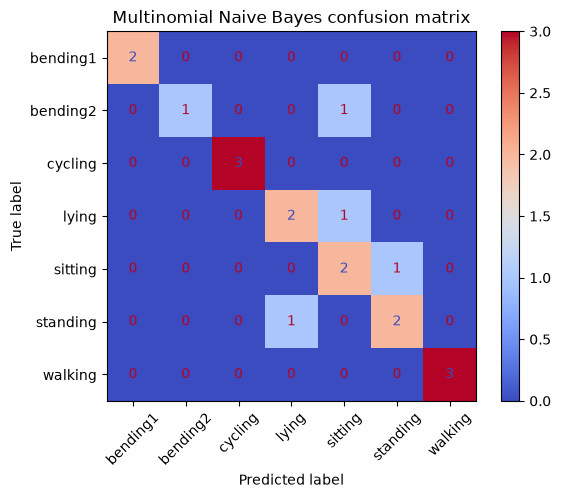

array([[2, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 1, 0, 0],
       [0, 0, 3, 0, 0, 0, 0],
       [0, 0, 0, 2, 1, 0, 0],
       [0, 0, 0, 0, 2, 1, 0],
       [0, 0, 0, 1, 0, 2, 0],
       [0, 0, 0, 0, 0, 0, 3]])

In [115]:
# Plot confusion matrix for Multinomial Naive Bayes Model
plot_confusion_matrix(mnb_best, X_mnb_test, y_mnb_test, 'Multinomial Naive Bayes confusion matrix')

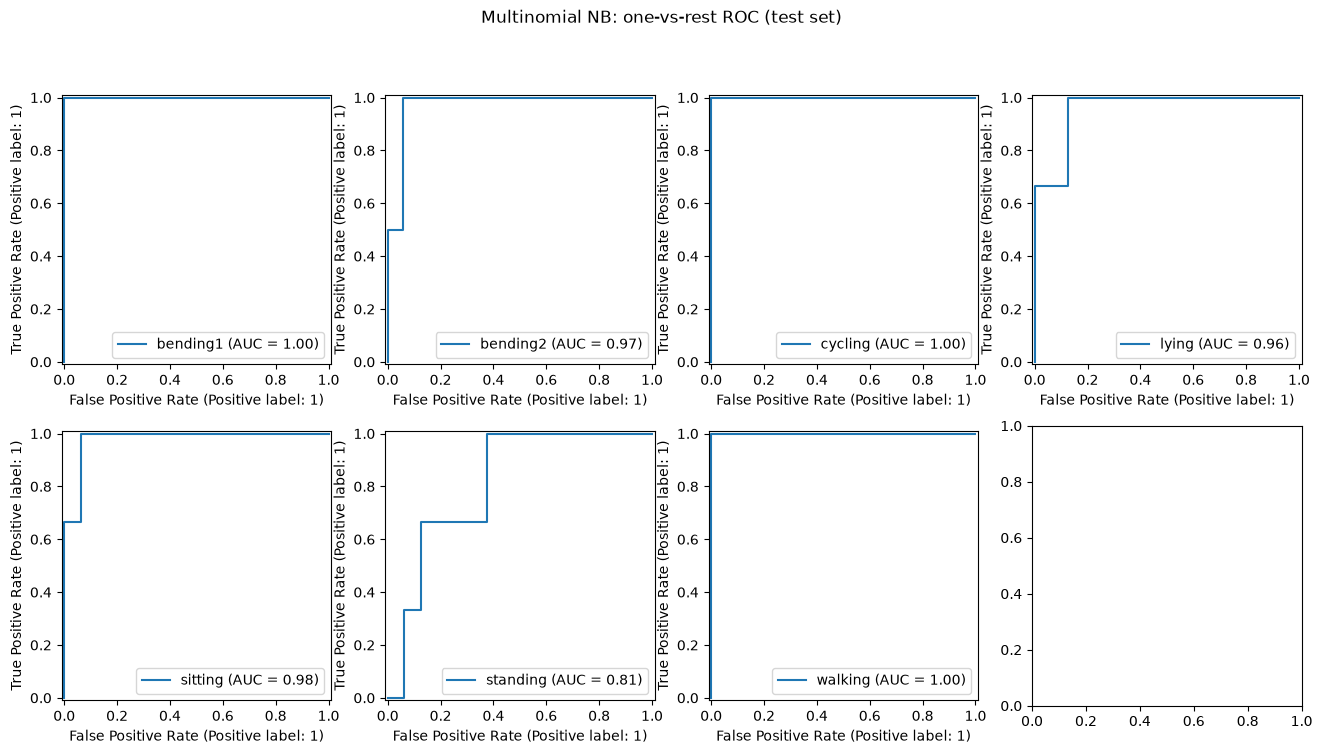

In [116]:
# Plot ROC curve
mnb_p_activities = mnb_best.predict_proba(X_mnb_test)   
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (i, activity) in zip(axes.flat, enumerate(mnb_best.classes_)):  # Display all ROC curves separately
    mnb_y_true = (y_mnb_test == activity)
    mnb_y_score = mnb_p_activities[:, i]
    RocCurveDisplay.from_predictions(mnb_y_true, mnb_y_score, name=activity, ax=ax)

fig.suptitle('Multinomial NB: one-vs-rest ROC (test set)')  # Add title label
plt.show()

In [118]:
# Store the test and train error into variables
gnb_train_error = 1 - gnb_best.score(X_nb, y_nb)
gnb_test_error  = 1 - gnb_best.score(X_nb_test, y_nb_test)

mnb_train_error = 1 - mnb_best.score(X_mnb, y_mnb)
mnb_test_error  = 1 - mnb_best.score(X_mnb_test, y_mnb_test)

# Print results in format for easier viewing
print(f"{'Model':<16}{'Train error':>12}{'Test error':>12}")
print(f"{'Gaussian NB':<16}{gnb_train_error:>12.3f}{gnb_test_error:>12.3f}")
print(f"{'Multinomial NB':<16}{mnb_train_error:>12.3f}{mnb_test_error:>12.3f}")

Model            Train error  Test error
Gaussian NB            0.029       0.105
Multinomial NB         0.130       0.211


#### ii. Comparison

Compare the results
The Gaussian Naive Bayes method had both a lower train and test error than the Multinomial Naive Bayes, showing better performance on the data given. Both show a gap between train and test error, but with sparser data (19 instances) each misclassification moves the error up by 1/19 (about .05).

Which method is better for multinomial classification?
The gaussian naive bayes method ties for test error with the L1 multinomial regression method at .105, both misclassifiying 2 out of the 19 test instances. However, Gaussian method takes less compute and can be calculated more simply (does not need to calculate c) and therefore would be a better option in this situation.

## 3. ISLR 4.8.3

Question: Suppose we have K classes, and an observation belongs to the kth class then X comes from a one-dimensional normal distribution, X ~ N. 

"Prove in this case Bayes classifier is not linear"

Bayes theroem:
$$ p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)} $$ (3.3.1)

Normal density is given:
$$ f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left( -\frac{1}{2\sigma_k^2}(x - \mu_k)^2 \right) $$ (3.3.2)

Calculate p_k without making the assumption that σ21 = · · · = σ2:
Plugging 3.3.2 (f_k(x)) into 3.3.1 (p_k(x)):
Since sigma is not equal everywhere, each class will have it's own sigma (σ_k), and p_k(x) can be written as such:
$$ p_k(x) = \frac{\pi_k \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left( -\frac{1}{2\sigma_k^2}(x - \mu_k)^2 \right)}{\sum_{l=1}^{K} \pi_l \frac{1}{\sqrt{2\pi}\,\sigma_l} \exp\left( -\frac{1}{2\sigma_l^2}(x - \mu_l)^2 \right)} $$ (3.3.3)

Since the denominator is the same for every class, the Bayes classifier assigns x to the class with the largest numerator (highest probability).

Next, we take the log of numerator of 3.3.3 and rearranging the terms gives us:
$$\log(\pi_k f_k(x))$$
(3.3.4)
which also expands  to:
$$ \log\left( \pi_k \cdot \frac{1}{\sqrt{2\pi}\,\sigma_k} \exp\left( -\frac{(x-\mu_k)^2}{2\sigma_k^2} \right) \right) $$
(3.3.5)

Since log(a*b*c) simplifies to loga + logb + log c, 3.3.5 can be simplified to:
$$ \log\pi_k + \log\frac{1}{\sqrt{2\pi}\,\sigma_k} - \frac{(x-\mu_k)^2}{2\sigma_k^2} $$
(3.3.6)

Then, (x-mu_k)^2 can also be written as: (x-mu)(x-mu) --> x^2 -2mux +mu2: $$(x-\mu_k)^2 = x^2 - 2\mu_k x + \mu_k^2$$
(3.3.7)

Plugging 3.3.7 back into 3.3.6 gets us:
$$ \log\pi_k + \log\frac{1}{\sqrt{2\pi}\,\sigma_k} - \frac{x^2 - 2\mu_k x + \mu_k^2}{2\sigma_k^2} $$
(3.3.8)

3.3.8 simplifes to $$ \log\pi_k + \log\frac{1}{\sqrt{2\pi}\,\sigma_k} - \frac{x^2}{2\sigma_k^2} + \frac{\mu_k x}{\sigma_k^2} - \frac{\mu_k^2}{2\sigma_k^2} $$
(3.3.9)


In the LDA the Bayes decision boundary is the point for which $\delta_1(x) = \delta_2(x)$; which amounts to:

$$ x = \frac{\mu_1^2 - \mu_2^2}{2(\mu_1 - \mu_2)} = \frac{\mu_1 + \mu_2}{2} $$
(3.3.10)

In the QDA version (3.3.9), each class has its own $\sigma_k$. The $x^2$ terms for two classes, $-\frac{x^2}{2\sigma_1^2}$ and $-\frac{x^2}{2\sigma_2^2}$, are not equal when $\sigma_1 \neq \sigma_2$, so they do not cancel when setting $\delta_1(x) = \delta_2(x)$. The $x^2$ term remains, so the Bayes classifier is not linear and it is quadratic in terms of x.

## 4. ISLR 4.8.7

This is binary classification problem ("yes" or "no" on dividend), with one feature (X = last year's percentage profit). 
We are given:
- Xbar = 10 for companies in class Y (1)
- Xbar = 0 for companies in class N (0)
- The variance (sigma^2) for both companies = 36
- 80% of all companies are Y // p(Y) = .8
- Normal distribution
What is p(Y | X=4)?

Bayes =
P(A | B) = [P(B|A)* P(A)] / P(B)
P(Y | X=4) = P(X=4|Y)·0.8 / [P(X=4|Y)·0.8 + P(X=4|N)·0.2]

Since σ² = 36 → σ = 6, then 2σ = 12

In [36]:
# Function to calculate CI interval range with default 95
def calculate_ci(mean: float, sigma: float, level: float = 95) -> tuple[float, float]:
    z = norm.ppf(1 - (1 - level / 100) / 2)   # 95 → 1.96
    result = mean - z * sigma, mean + z * sigma
    return result

# Assign knowns to variable
x = 4
sigma = 6
prob_yes_class = .8
prob_no_class = 1 - prob_yes_class
xbar_yes = 10  # xbar for 'y' class = 10
xbar_no = 0    # xbar for 'n' class = 0

In [41]:
# Calculate normal density for both classes if x=4
yes_density = norm.pdf(4, loc=10, scale=6)  # Likelihood for 'y' class with xbar 10, sigma 6
no_density = norm.pdf(4, loc=0, scale=6)    # Likelihood for 'n' class with xbar 0, sigma 6

print(yes_density, no_density)

# Calculate prior likelihood for each group
proportion_yes = prob_yes_class * yes_density  # Calculate the likelihood of yes given x=4
proportion_no = prob_no_class * no_density # Calculate the likelihood of no given x=4

print(proportion_yes, proportion_no)

# Plug into bayes
prob_x = proportion_yes + proportion_no  # probability that x=4 out of all classes
p_yes = proportion_yes / prob_x
print(p_yes)

# Print result
print(f"Probability a company will issue a dividend (fall in class Y) given x=4 is: {p_yes:.3f}")

0.04032845408652389 0.053241334253725375
0.03226276326921911 0.010648266850745073
0.7518524532975261
Probability a company will issue a dividend (fall in class Y) given x=4 is: 0.752


## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9